In [51]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier

In [52]:
borders = [0, 18, 30, 40, 50, 60, 70, 80]
labels = ['0-17', '18-29', '30-39', '40-49', '50-59', '60-69', '70-79'] # '0-17', '18-29', '30-39', '40-49', '50-59', '60-69', '70-79'

In [53]:
spaceship_titanic_df = pd.read_csv("./dane.csv")

spaceship_titanic_df['PassengerGroup'] = spaceship_titanic_df['PassengerId'].str.split('_').str[0]
spaceship_titanic_df.loc[~spaceship_titanic_df.Name.isna(), 'Forename'] = spaceship_titanic_df.loc[~spaceship_titanic_df.Name.isna(), 'Name'].str.split(' ').str[0]
spaceship_titanic_df.loc[~spaceship_titanic_df.Name.isna(), 'Surname'] = spaceship_titanic_df.loc[~spaceship_titanic_df.Name.isna(), 'Name'].str.split(' ').str[1]
spaceship_titanic_df.loc[~spaceship_titanic_df.Cabin.isna(), 'CabinDeck'] = spaceship_titanic_df.loc[~spaceship_titanic_df.Cabin.isna(), 'Cabin'].str.split('/').str[0]
spaceship_titanic_df.loc[~spaceship_titanic_df.Cabin.isna(), 'CabinSide'] = spaceship_titanic_df.loc[~spaceship_titanic_df.Cabin.isna(), 'Cabin'].str.split('/').str[2]
spaceship_titanic_df.loc[~spaceship_titanic_df[['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']].isna().any(axis = 1), 'Total'] = spaceship_titanic_df.loc[~spaceship_titanic_df[['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']].isna().any(axis = 1), ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']].sum(axis = 1)
spaceship_titanic_df.loc[~spaceship_titanic_df.Age.isna(), 'AgeGroup'] = pd.cut(
    spaceship_titanic_df.loc[~spaceship_titanic_df.Age.isna(), 'Age'], 
    bins = borders, 
    labels = labels, 
    right = False
)

display(spaceship_titanic_df)

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,...,VRDeck,Name,Transported,PassengerGroup,Forename,Surname,CabinDeck,CabinSide,Total,AgeGroup
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,...,0.0,Maham Ofracculy,False,0001,Maham,Ofracculy,B,P,0.0,30-39
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,...,44.0,Juanna Vines,True,0002,Juanna,Vines,F,S,736.0,18-29
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,...,49.0,Altark Susent,False,0003,Altark,Susent,A,S,10383.0,50-59
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,...,193.0,Solam Susent,False,0003,Solam,Susent,A,S,5176.0,30-39
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,...,2.0,Willy Santantines,True,0004,Willy,Santantines,F,S,1091.0,0-17
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,9276_01,Europa,False,A/98/P,55 Cancri e,41.0,True,0.0,6819.0,0.0,...,74.0,Gravior Noxnuther,False,9276,Gravior,Noxnuther,A,P,8536.0,40-49
8689,9278_01,Earth,True,G/1499/S,PSO J318.5-22,18.0,False,0.0,0.0,0.0,...,0.0,Kurta Mondalley,False,9278,Kurta,Mondalley,G,S,0.0,18-29
8690,9279_01,Earth,False,G/1500/S,TRAPPIST-1e,26.0,False,0.0,0.0,1872.0,...,0.0,Fayey Connon,True,9279,Fayey,Connon,G,S,1873.0,18-29
8691,9280_01,Europa,False,E/608/S,55 Cancri e,32.0,False,0.0,1049.0,0.0,...,3235.0,Celeon Hontichre,False,9280,Celeon,Hontichre,E,S,4637.0,30-39


In [54]:
#print(spaceship_titanic_df.shape)
#print(spaceship_titanic_df.columns)
#print(spaceship_titanic_df.dtypes)

#print(spaceship_titanic_df.isna().sum())

In [55]:
sns.set_theme(style = "darkgrid")

sns.set_theme(rc={'figure.figsize': (7, 6)})

<span style = "font-size: 30px; color: green;">Which passengers are in CryoSleep?</span>

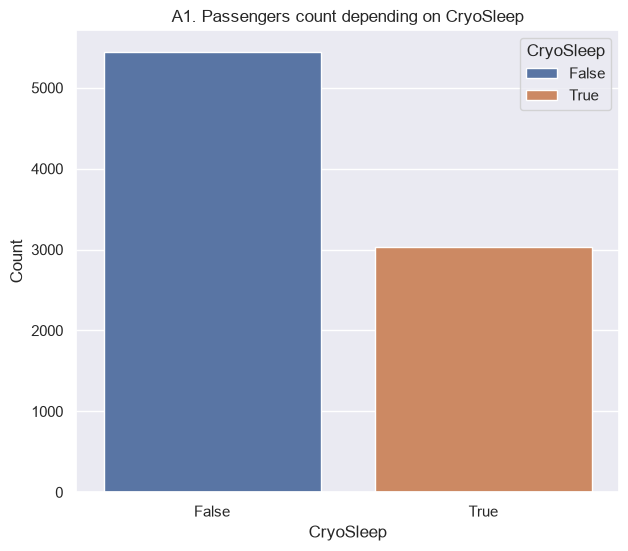

In [56]:
spaceship_titanic_df_a = spaceship_titanic_df[~spaceship_titanic_df.CryoSleep.isna()]

count_by_cryosleep = spaceship_titanic_df_a.groupby('CryoSleep').agg(
    count = ('CryoSleep', "count")
)

ax = sns.barplot(
    data = count_by_cryosleep,
    x = 'CryoSleep',
    hue = 'CryoSleep',
    y = 'count'
)

plt.title('A1. Passengers count depending on CryoSleep')
plt.xlabel('CryoSleep')
plt.ylabel('Count')

plt.show()

* Around 2/3 of all passengers are not in CryoSleep and around 1/3 are in CryoSleep

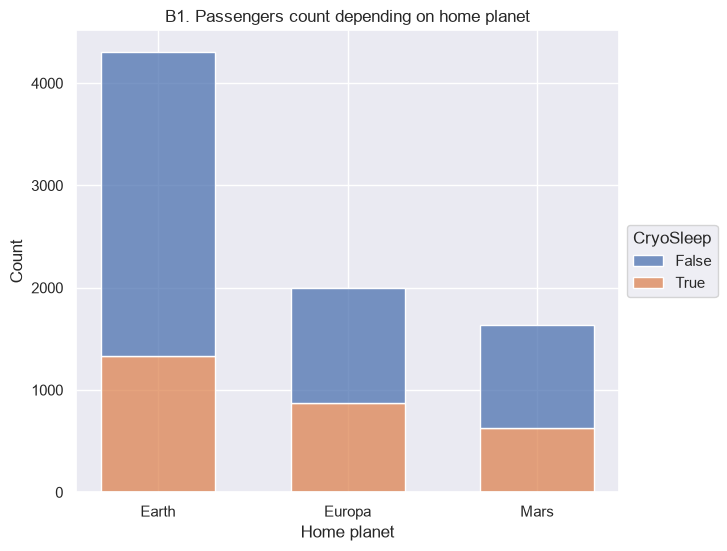

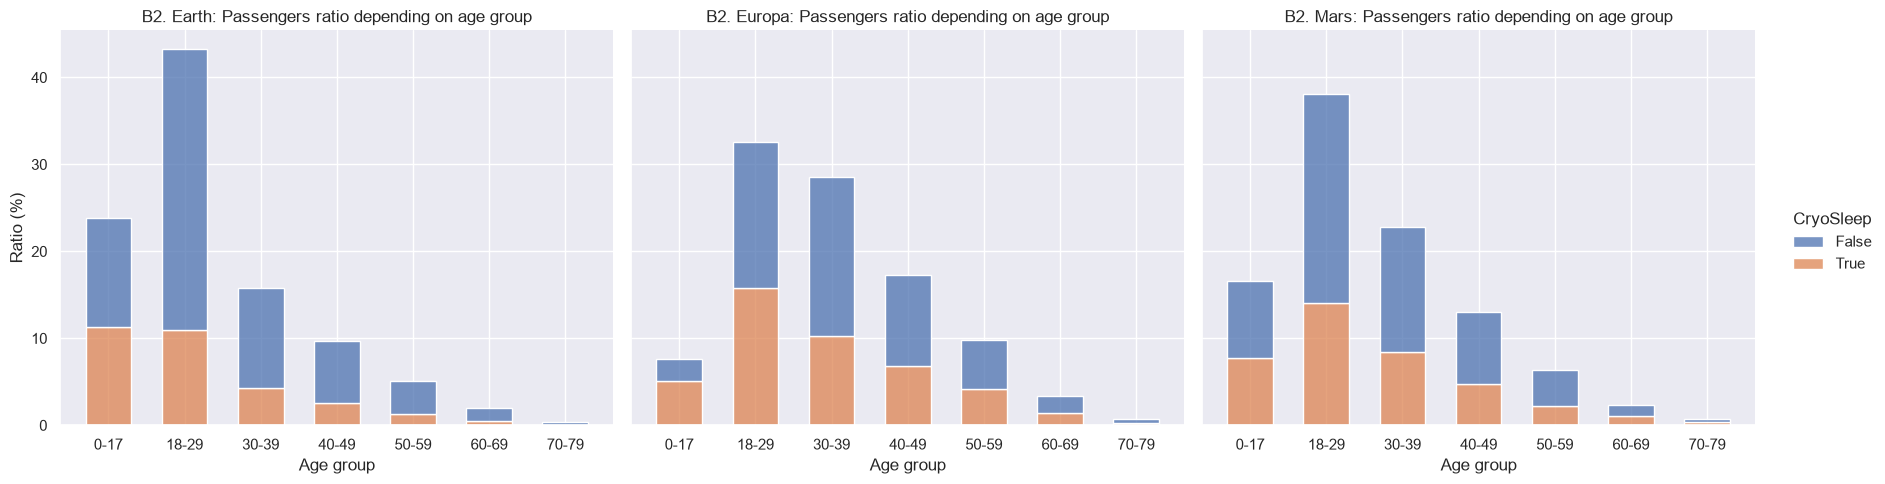

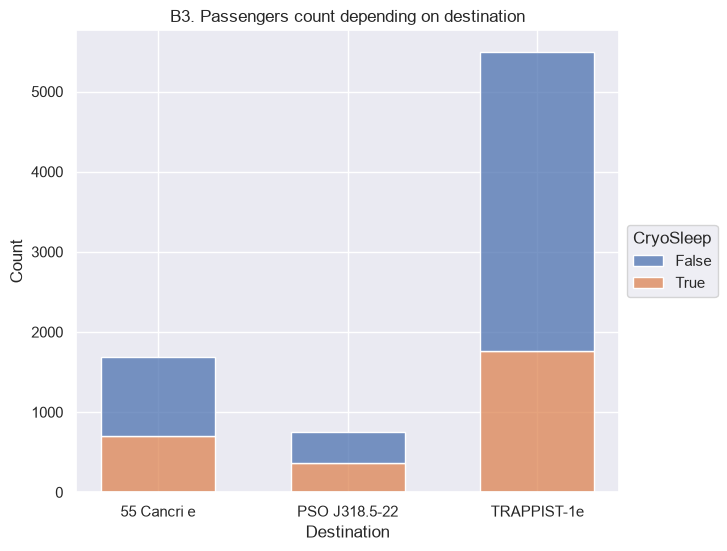

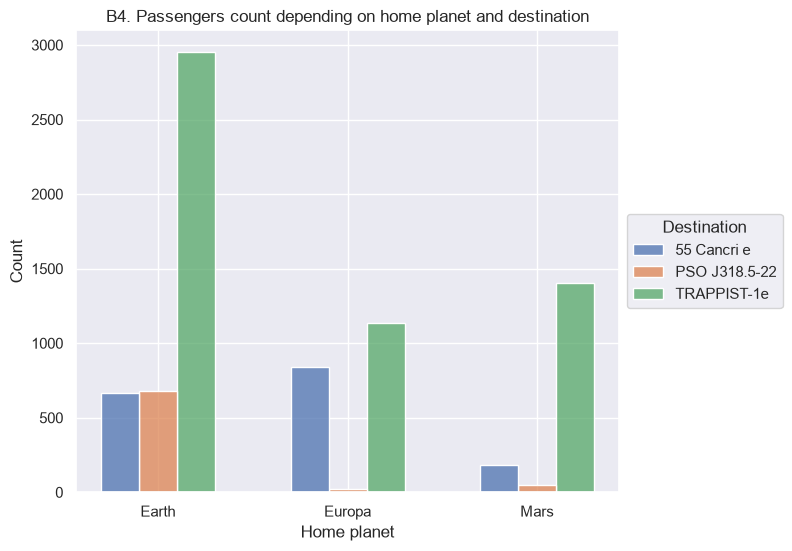

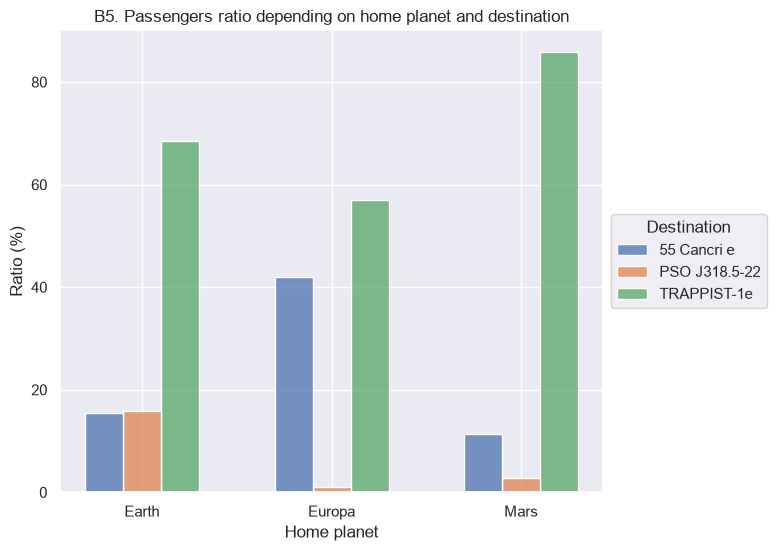

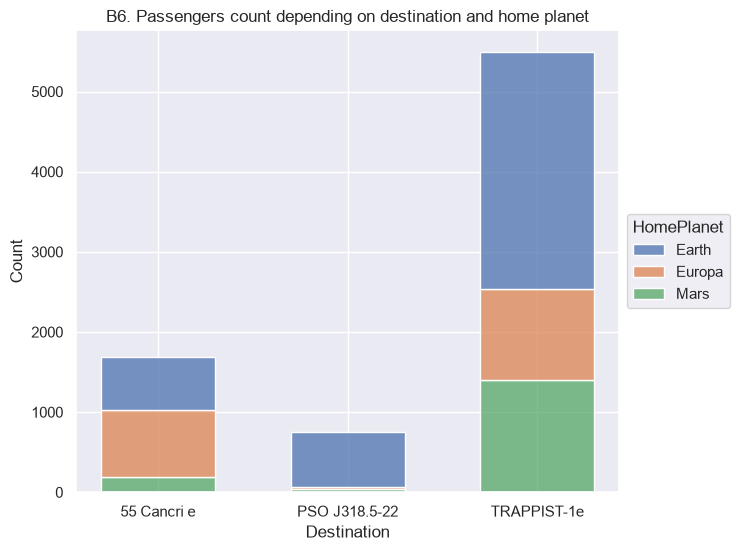

In [57]:
spaceship_titanic_df_b = spaceship_titanic_df[~spaceship_titanic_df[['CryoSleep', 'Age', 'HomePlanet', 'Destination']].isna().any(axis = 1)]

count_by_homeplanet_cryosleep = spaceship_titanic_df_b.groupby(['HomePlanet', 'CryoSleep']).agg(
    count = ('CryoSleep', "count")
)

ax = sns.histplot(
    data = count_by_homeplanet_cryosleep,
    x = 'HomePlanet',
    hue = 'CryoSleep',
    weights = 'count',
    multiple = 'stack',
    shrink = 0.6
)

sns.move_legend(ax, "center left", bbox_to_anchor = (1, 0.5))

plt.title('B1. Passengers count depending on home planet')
plt.xlabel('Home planet')
plt.ylabel('Count')

plt.show()

pom_homeplanet_ratio_by_agegroup = spaceship_titanic_df_b.groupby(['HomePlanet']).agg(
    pom_count = ('HomePlanet', "count")
)

homeplanet_ratio_by_agegroup = spaceship_titanic_df_b.groupby(['HomePlanet', 'AgeGroup', 'CryoSleep']).agg(
   ratio = ('CryoSleep', "count")
).reset_index().set_index('HomePlanet')
homeplanet_ratio_by_agegroup = homeplanet_ratio_by_agegroup.merge(pom_homeplanet_ratio_by_agegroup, on = ['HomePlanet'], how = 'left')
homeplanet_ratio_by_agegroup['ratio'] = (homeplanet_ratio_by_agegroup['ratio'] / homeplanet_ratio_by_agegroup['pom_count']) * 100

g = sns.displot(
    data = homeplanet_ratio_by_agegroup,
    x = 'AgeGroup',
    hue = 'CryoSleep',
    weights = 'ratio',
    col = 'HomePlanet',
    multiple = 'stack',
    shrink = 0.6,
    aspect = 1.2
)

g.set_axis_labels('Age group', 'Ratio (%)')
g.set_titles('B2. {col_name}: Passengers ratio depending on age group')

plt.show()

count_by_destination_cryosleep = spaceship_titanic_df_b.groupby(['Destination', 'CryoSleep']).agg(
    count = ('Destination', "count")
)

ax = sns.histplot(
    data = count_by_destination_cryosleep,
    x = 'Destination',
    hue = 'CryoSleep',
    weights = 'count',
    multiple = 'stack',
    shrink = 0.6
)

sns.move_legend(ax, "center left", bbox_to_anchor = (1, 0.5))

plt.title('B3. Passengers count depending on destination')
plt.xlabel('Destination')
plt.ylabel('Count')

plt.show()

pom_count_ratio_by_homeplanet_destination = spaceship_titanic_df_b.groupby(['HomePlanet']).agg(
    pom_count = ('HomePlanet', "count")
)

count_ratio_by_homeplanet_destination = spaceship_titanic_df_b.groupby(['HomePlanet', 'Destination']).agg(
    count = ('Destination', "count")
).reset_index().set_index('HomePlanet')
count_ratio_by_homeplanet_destination = count_ratio_by_homeplanet_destination.merge(pom_count_ratio_by_homeplanet_destination, on = ['HomePlanet'], how = 'left')
count_ratio_by_homeplanet_destination['ratio'] = count_ratio_by_homeplanet_destination['count'] / count_ratio_by_homeplanet_destination['pom_count'] * 100

for weight in ['count', 'ratio']:
    ax = sns.histplot(
        data = count_ratio_by_homeplanet_destination,
        x = 'HomePlanet',
        hue = 'Destination',
        weights = weight,
        multiple = 'dodge',
        shrink = 0.6
    )
    
    sns.move_legend(ax, "center left", bbox_to_anchor = (1, 0.5))
    
    plt.title(f'{'B4' if weight == 'count' else 'B5'}. Passengers {'count' if weight == 'count' else 'ratio'} depending on home planet and destination')
    plt.xlabel('Home planet')
    plt.ylabel('Count' if weight == 'count' else 'Ratio (%)')
    
    plt.show()

count_by_destination_homeplanet = spaceship_titanic_df_b.groupby(['Destination', 'HomePlanet']).agg(
    count = ('HomePlanet', "count")
)

ax = sns.histplot(
    data = count_by_destination_homeplanet,
    x = 'Destination',
    hue = 'HomePlanet',
    weights = 'count',
    multiple = 'stack',
    shrink = 0.6
)

sns.move_legend(ax, "center left", bbox_to_anchor = (1, 0.5))

plt.title('B6. Passengers count depending on destination and home planet')
plt.xlabel('Destination')
plt.ylabel('Count')

plt.show()

<span style = "font-size: 20px; color: green;">Where are passengers from and where are they travelling?</span>

* More than 50% of all passengers are from Earth, ~25% from Europa and ~20% from Mars
* Most passengers in CryoSleep are from Earth (~45%), but on Earth percentage of passengers in CryoSleep is the lowest (~30%)
* On Europa percentage of passengers in CryoSleep is the highest (~45%) <br><br>

* Most passengers are travelling to TRAPPIST-1e (~70%), fewest to PSO J318.5-22 (~10%)
* Most passengers in CryoSleep are travelling to TRAPPIST-1e (~65%), but on TRAPPIST-1e percentage of passengers having been in CryoSleep will be the lowest (~30%)

<span style = "font-size: 20px; color: green;">How old are passengers from different planets?</span>

* On every planet ~60% of all passengers are between 18 and 39 years old (on Earth and Mars ~40% are between 18 and 29 and on Europa ~30% of passengers are between 18-29 and 30-39)
* On Earth percentage of children is the highest (~25%) while in Europa it is the lowest (~10%)
* On every planet very few people are 50+ years old (maximum ~15% in Europa) <br><br>

* On every planet percentage of children in CryoSleep is very high (more than 50%)
* On Earth only ~15% of passengers between 18-39 are in CryoSleep, ~25% on Mars and ~45% on Europa

<span style = "font-size: 20px; color: green;">Which route is the most popular?</span>

* Most popular route is Earth-TRAPPIST-1e (~70% passengers from Earth travel there)
* ~50% of passengers from Europa travel to 55 Cancri e and TRAPPIST-1e
* Passengers from Mars almost only travel to TRAPPIST-1e (~90%) <br><br>

* On TRAPPIST-1e more than 50% passengers will be from Earth
* Almost only passengers from Earth travel to PSO J318.5-22 (~350 not in CryoSleep and in CryoSleep)

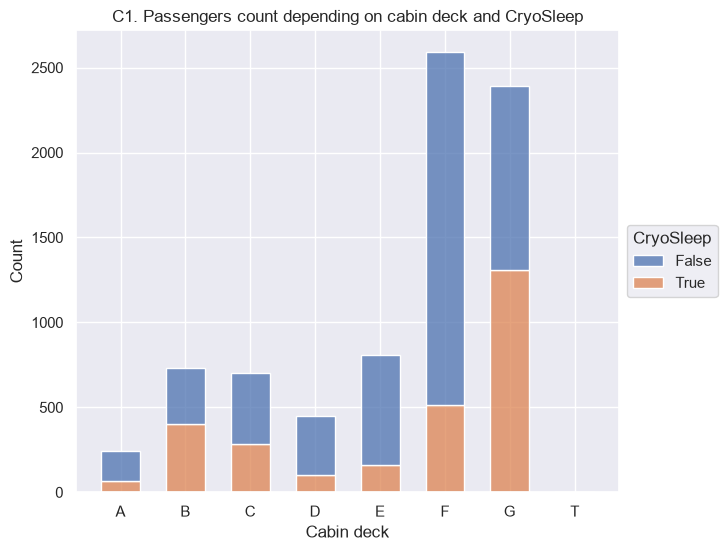

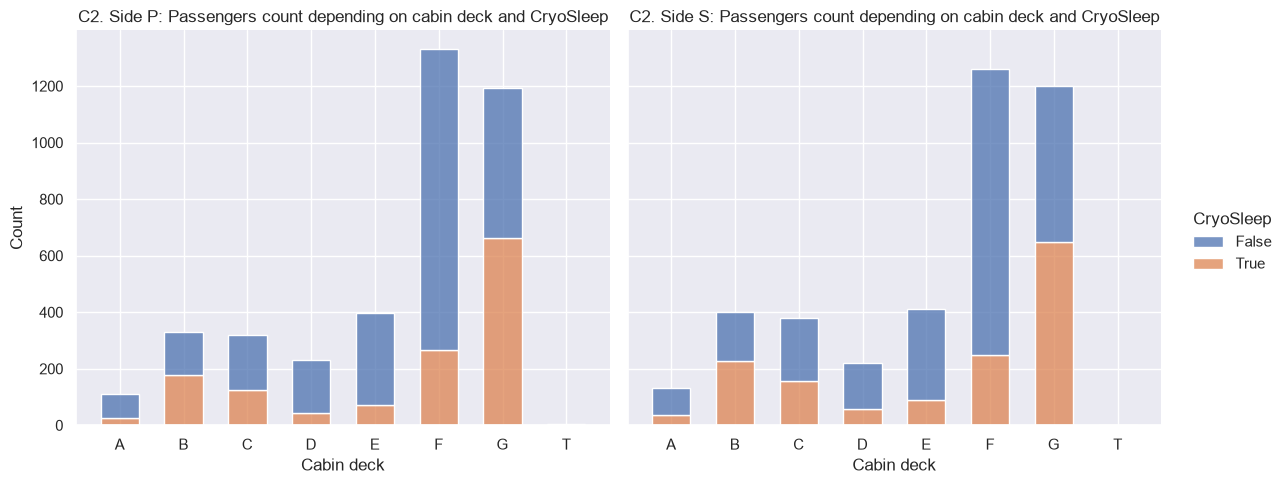

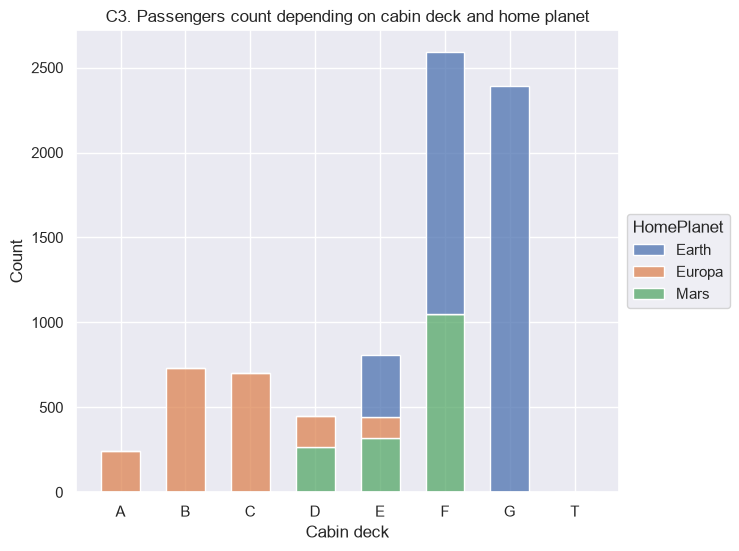

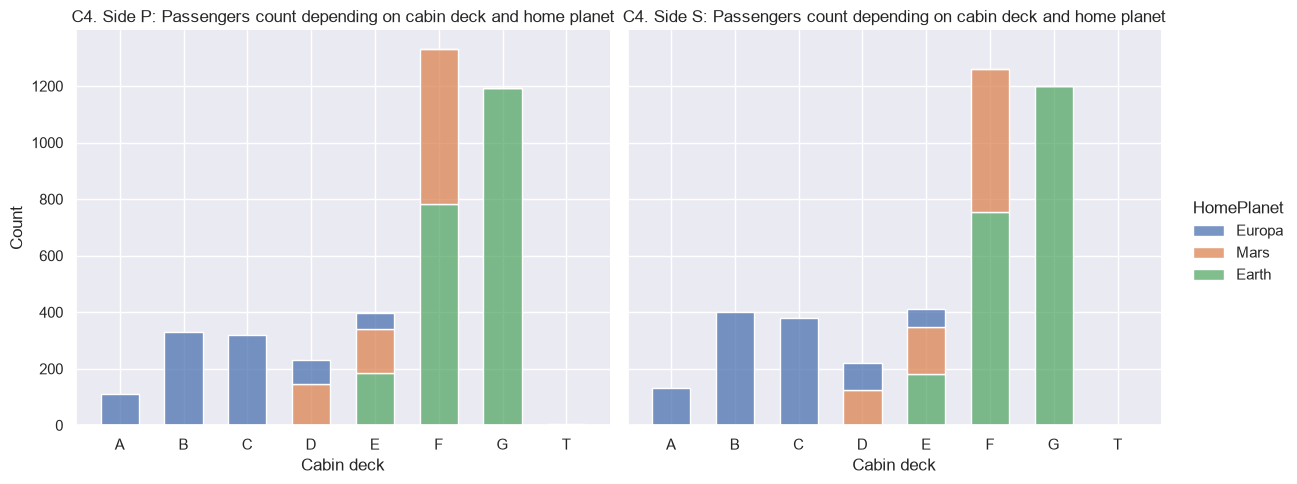

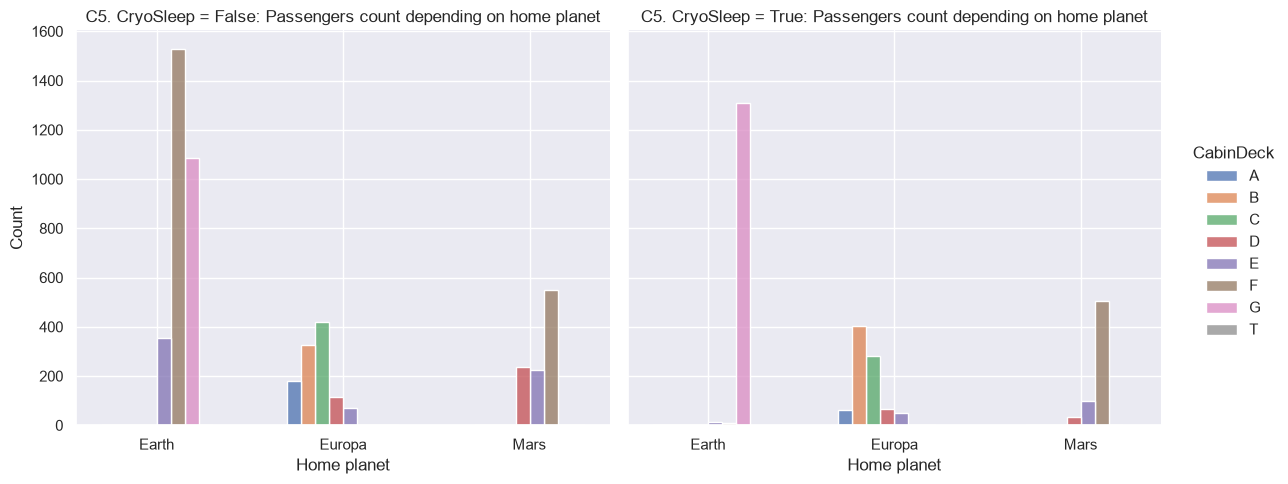

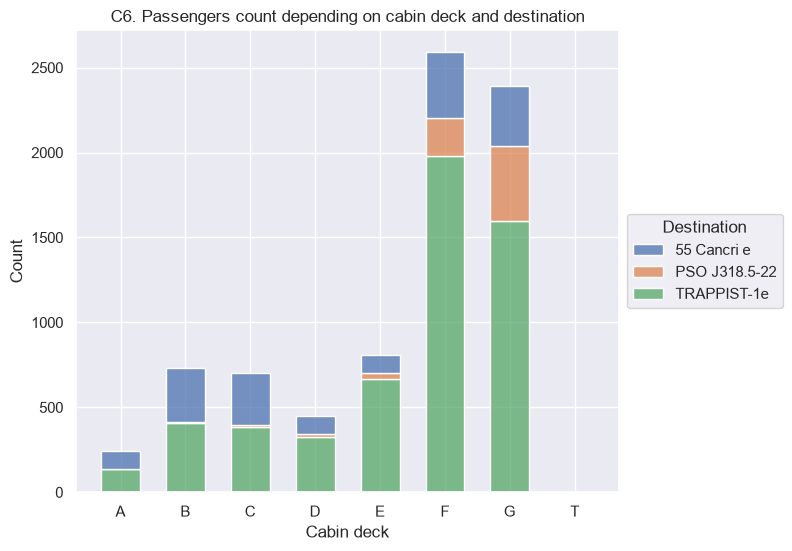

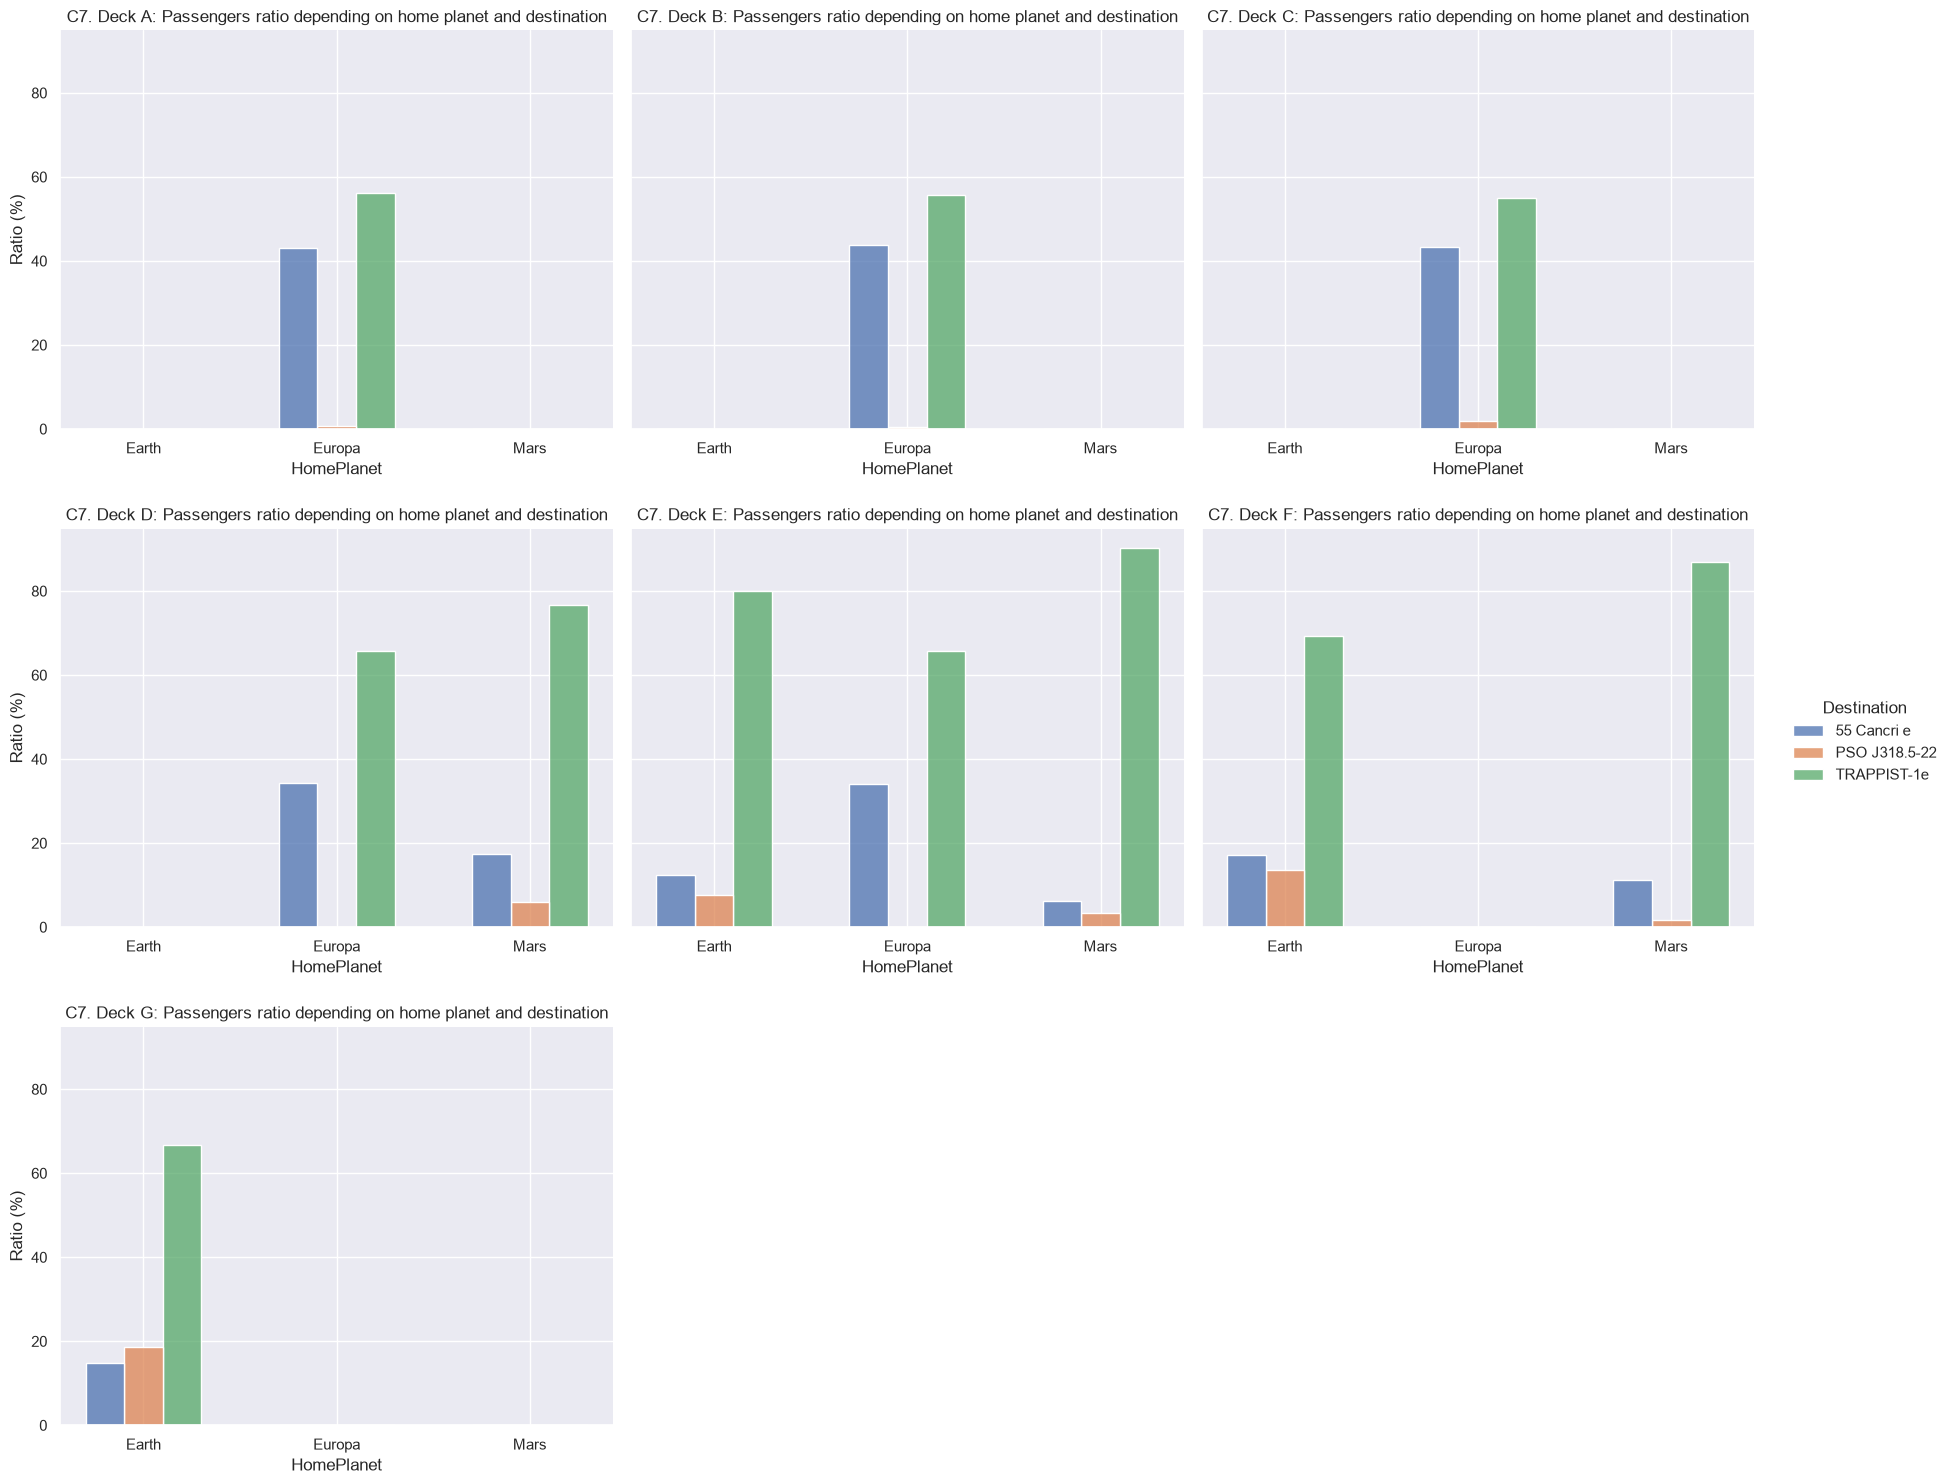

In [58]:
spaceship_titanic_df_c = spaceship_titanic_df[~spaceship_titanic_df[['CryoSleep', 'CabinDeck', 'CabinSide', 'HomePlanet', 'Destination']].isna().any(axis = 1)]

count_by_cabindeck_cryosleep = spaceship_titanic_df_c.groupby(['CabinDeck', 'CryoSleep']).agg(
    count = ('CabinDeck', "count")
)

ax = sns.histplot(
    data = count_by_cabindeck_cryosleep,
    x = 'CabinDeck',
    hue = 'CryoSleep',
    weights = 'count',
    multiple = 'stack',
    shrink = 0.6
)

sns.move_legend(ax, "center left", bbox_to_anchor = (1, 0.5))

plt.title('C1. Passengers count depending on cabin deck and CryoSleep')
plt.xlabel('Cabin deck')
plt.ylabel('Count')

plt.show()

cabinside_count_by_cabindeck_cryosleep = spaceship_titanic_df_c.groupby(['CabinSide', 'CabinDeck', 'CryoSleep']).agg(
    count = ('CryoSleep', "count")
)

g = sns.displot(
    data = cabinside_count_by_cabindeck_cryosleep,
    x = 'CabinDeck',
    hue = 'CryoSleep',
    weights = 'count',
    col = 'CabinSide',
    multiple = 'stack',
    shrink = 0.6,
    aspect = 1.2
)

g.set_axis_labels('Cabin deck', 'Count')
g.set_titles('C2. Side {col_name}: Passengers count depending on cabin deck and CryoSleep')

plt.show()

count_by_cabindeck_homeplanet = spaceship_titanic_df_c.groupby(['CabinDeck', 'HomePlanet']).agg(
    count = ('HomePlanet', "count")
)

ax = sns.histplot(
    data = count_by_cabindeck_homeplanet,
    x = 'CabinDeck',
    hue = 'HomePlanet',
    hue_order = sorted(count_by_cabindeck_homeplanet.reset_index()['HomePlanet'].unique()),
    weights = 'count',
    multiple = 'stack',
    shrink = 0.6
)

sns.move_legend(ax, "center left", bbox_to_anchor = (1, 0.5))

plt.title('C3. Passengers count depending on cabin deck and home planet')
plt.xlabel('Cabin deck')
plt.ylabel('Count')

plt.show()

cabinside_count_by_cabindeck_homeplanet = spaceship_titanic_df_c.groupby(['CabinSide', 'CabinDeck', 'HomePlanet']).agg(
    count = ('HomePlanet', "count")
)

g = sns.displot(
    data = cabinside_count_by_cabindeck_homeplanet,
    x = 'CabinDeck',
    hue = 'HomePlanet',
    weights = 'count',
    col = 'CabinSide',
    multiple = 'stack',
    shrink = 0.6,
    aspect = 1.2
)

g.set_axis_labels('Cabin deck', 'Count')
g.set_titles('C4. Side {col_name}: Passengers count depending on cabin deck and home planet')

plt.show()

cryosleep_count_by_homeplanet_cabindeck = spaceship_titanic_df_c.groupby(['CryoSleep', 'HomePlanet', 'CabinDeck']).agg(
    count = ('CabinDeck', "count")
)

g = sns.displot(
    data = cryosleep_count_by_homeplanet_cabindeck,
    x = 'HomePlanet',
    hue = 'CabinDeck',
    hue_order = sorted(cryosleep_count_by_homeplanet_cabindeck.reset_index()['CabinDeck'].unique()),
    weights = 'count',
    col = 'CryoSleep',
    multiple = 'dodge',
    shrink = 0.6,
    aspect = 1.2
)

g.set_axis_labels('Home planet', 'Count')
g.set_titles('C5. CryoSleep = {col_name}: Passengers count depending on home planet')

plt.show()

count_by_cabindeck_destination = spaceship_titanic_df_c.groupby(['CabinDeck', 'Destination']).agg(
    count = ('Destination', "count")
)

ax = sns.histplot(
    data = count_by_cabindeck_destination,
    x = 'CabinDeck',
    hue = 'Destination',
    hue_order = sorted(count_by_cabindeck_destination.reset_index()['Destination'].unique()),
    weights = 'count',
    multiple = 'stack',
    shrink = 0.6
)

sns.move_legend(ax, "center left", bbox_to_anchor = (1, 0.5))

plt.title('C6. Passengers count depending on cabin deck and destination')
plt.xlabel('Cabin deck')
plt.ylabel('Count')

plt.show()

cabindeck_ratio_by_homeplanet_destination = spaceship_titanic_df_c[~spaceship_titanic_df_c.CabinDeck.isin(['T'])].groupby(['CabinDeck', 'HomePlanet', 'Destination']).agg(
    ratio_2 = ('Destination', "count")
).reset_index()

cabindeck_ratio_by_homeplanet_destination = cabindeck_ratio_by_homeplanet_destination.merge(count_by_cabindeck_homeplanet, on = ['CabinDeck', 'HomePlanet'], how = 'left')
cabindeck_ratio_by_homeplanet_destination['ratio_2'] = cabindeck_ratio_by_homeplanet_destination['ratio_2'] / cabindeck_ratio_by_homeplanet_destination['count'] * 100

cabindeck_ratio_by_homeplanet_destination['HomePlanet'] = pd.Categorical(
    cabindeck_ratio_by_homeplanet_destination['HomePlanet'], 
    categories = sorted(cabindeck_ratio_by_homeplanet_destination['HomePlanet'].unique()), 
    ordered = True
)

g = sns.displot(
    data = cabindeck_ratio_by_homeplanet_destination,
    x = 'HomePlanet',
    hue = 'Destination',
    hue_order = sorted(cabindeck_ratio_by_homeplanet_destination['Destination'].unique()),
    weights = 'ratio_2',
    col = 'CabinDeck',
    col_wrap = 3,
    multiple = 'dodge',
    shrink = 0.6,
    aspect = 1.2
)

g.set_axis_labels('Home planet', 'Ratio (%)')
g.set_titles('C7. Deck {col_name}: Passengers ratio depending on home planet and destination')

for ax in g.axes.flatten():
    ax.tick_params(labelbottom = True)
    ax.set_xlabel('HomePlanet')
    ax.xaxis.label.set_visible(True)

g.fig.subplots_adjust(hspace = 0.25)

plt.show()

<span style = "font-size: 20px; color: green;">Which decks passengers live on?<span />

* More than 60% of all passengers live on decks F and G
* On deck T live less than 10 people
* Most passengers in CryoSleep live on deck G (little less than 1500) and most passengers not in CryoSleep live on deck F (more than 1500)<br><br>

* Only passengers from Europa live on decks A, B and C (~85% of all passengers from Europa)
* Only passengers from Earth live on deck G (~55% of all passengers from Earth)
* More than 60% passengers from Mars live on deck F<br><br>

* Passengers from Earth using CryoSleep live almost only on deck G
* Passengers from Mars using CryoSleep live almost only on deck F<br><br>

* ~50% of passengers on every deck A, B and C travel to both 55 Cancri e and TRAPPIST-1e (as expected because similar amount of passengers from Europa travel to both these planets)
* ~70% of passengers from decks F and G travel to TRAPPIST-1e (as expected because most passengers from Earth and Mars travel to TRAPPIST-1e)<br><br>

* On every deck percentages of passengers from given planet travelling to 55 Cancri e, PSO J318.5-22 or TRAPPIST-1e are similar to percentages on figure 6, which means that<br>
distribution of passengers from given planets based on where they travel is similar on every deck

<span style = "font-size: 30px; color: green;">How much money passengers spend?<span />

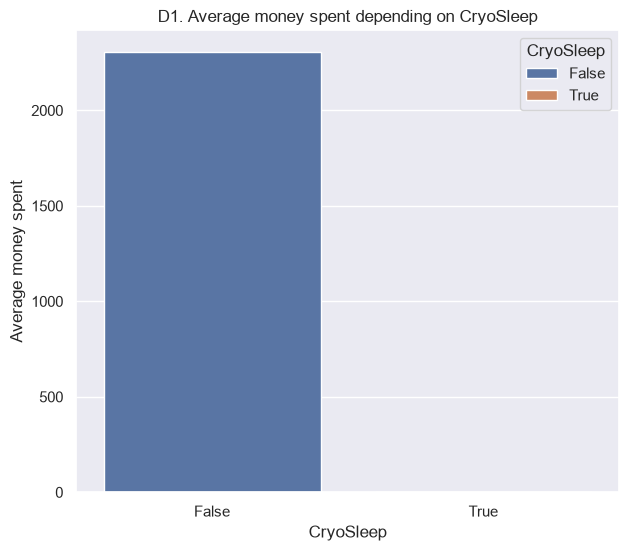

In [59]:
spaceship_titanic_df_d = spaceship_titanic_df[~spaceship_titanic_df[['CryoSleep', 'Total']].isna().any(axis = 1)]

avgmoneyspent_by_cryosleep = spaceship_titanic_df_d.groupby('CryoSleep').agg(
    mean = ('Total', "mean")
)

ax = sns.barplot(
    data = avgmoneyspent_by_cryosleep,
    x = 'CryoSleep',
    hue = 'CryoSleep',
    y = 'mean'
)

plt.title('D1. Average money spent depending on CryoSleep')
plt.xlabel('CryoSleep')
plt.ylabel('Average money spent')

plt.show()

* Only passengers not in CryoSleep spend money

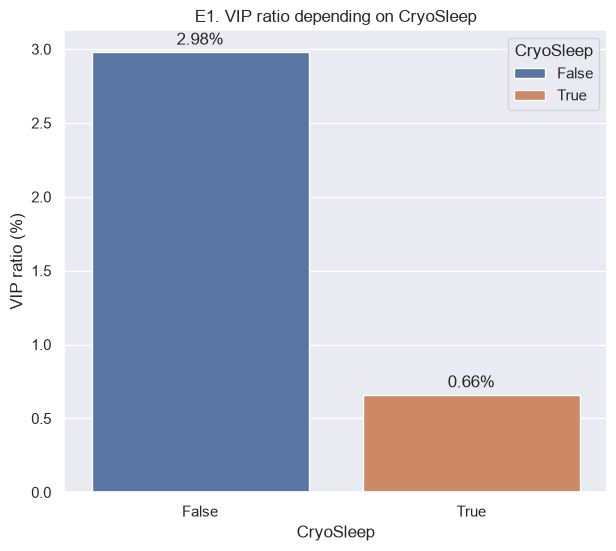

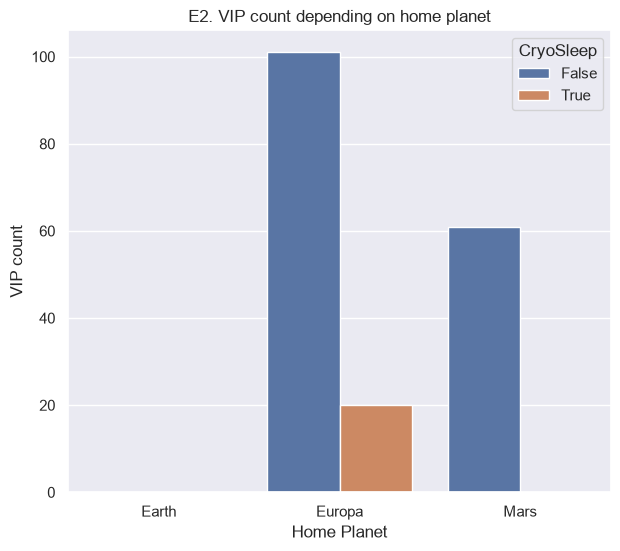

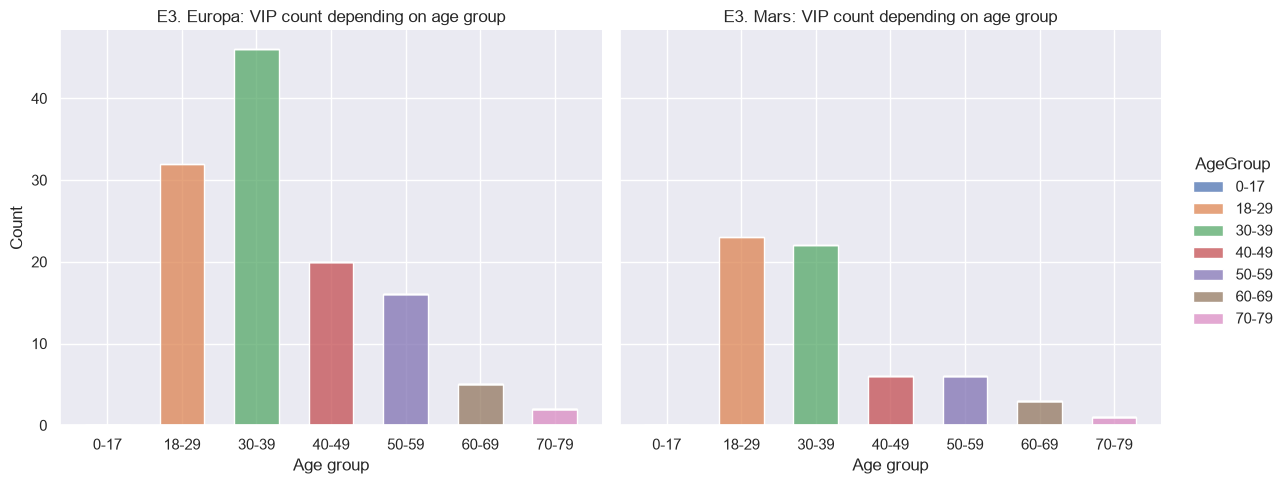

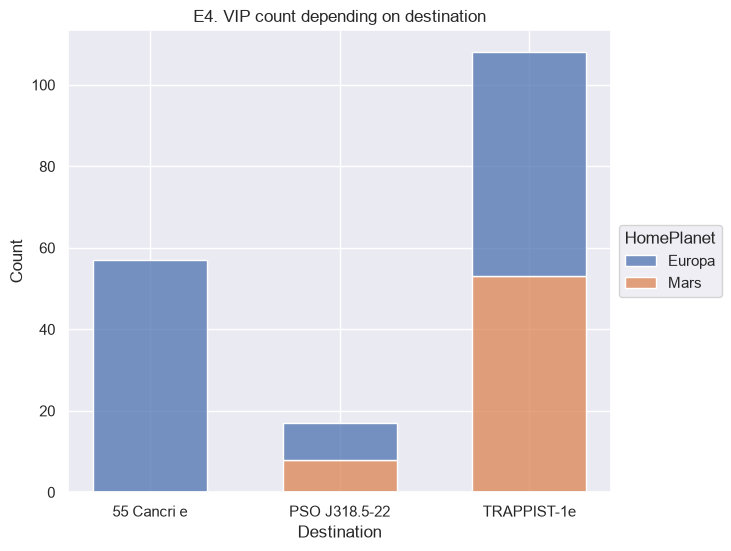

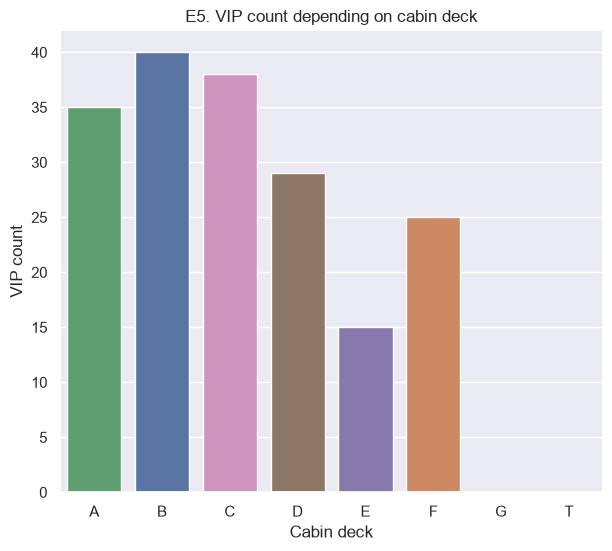

In [60]:
spaceship_titanic_df_e = spaceship_titanic_df[~spaceship_titanic_df[['HomePlanet', 'CryoSleep', 'Destination', 'VIP', 'CabinDeck', 'AgeGroup']].isna().any(axis = 1)]
spaceship_titanic_df_e = spaceship_titanic_df_e[spaceship_titanic_df_e.VIP == True]

vipratio_by_cryosleep = spaceship_titanic_df_e.groupby('CryoSleep').agg(
    ratio_2 = ('CryoSleep', "count")
)

vipratio_by_cryosleep['ratio_2'] = vipratio_by_cryosleep['ratio_2'] / count_by_cryosleep['count'] * 100

ax = sns.barplot(
    data = vipratio_by_cryosleep,
    x = 'CryoSleep',
    hue = 'CryoSleep',
    y = 'ratio_2'
)

plt.title('E1. VIP ratio depending on CryoSleep')
plt.xlabel('CryoSleep')
plt.ylabel('VIP ratio (%)')

for container in ax.containers:
    ax.bar_label(container, fmt = '%.2f%%', padding = 3)

plt.show()

vipcount_by_homeplanet = spaceship_titanic_df_e.groupby(['HomePlanet', 'CryoSleep']).agg(
    count = ('CryoSleep', "count")
)

ax = sns.barplot(
    data = vipcount_by_homeplanet,
    x = 'HomePlanet',
    order = sorted(spaceship_titanic_df['HomePlanet'].dropna().unique()),
    hue = 'CryoSleep',
    y = 'count'
)

plt.title('E2. VIP count depending on home planet')
plt.xlabel('Home Planet')
plt.ylabel('VIP count')

plt.show()

homeplanet_vipcount_by_agegroup = spaceship_titanic_df_e.groupby(['HomePlanet', 'AgeGroup']).agg(
   count = ('AgeGroup', "count")
)

pom_homeplanet_vipcount_by_agegroup = pd.MultiIndex.from_product(
    [spaceship_titanic_df_e['HomePlanet'].unique(), labels], 
    names = ['HomePlanet', 'AgeGroup']
)

homeplanet_vipcount_by_agegroup = homeplanet_vipcount_by_agegroup.reindex(pom_homeplanet_vipcount_by_agegroup, fill_value = 0)

g = sns.displot(
    data = homeplanet_vipcount_by_agegroup,
    x = 'AgeGroup',
    hue = 'AgeGroup',
    weights = 'count',
    col = 'HomePlanet',
    multiple = 'stack',
    shrink = 0.6,
    aspect = 1.2
)

g.set_axis_labels('Age group', 'Count')
g.set_titles('E3. {col_name}: VIP count depending on age group')

plt.show()

vipcount_by_destination = spaceship_titanic_df_e.groupby(['Destination', 'HomePlanet']).agg(
    count = ('HomePlanet', "count")
)

ax = sns.histplot(
    data = vipcount_by_destination,
    x = 'Destination',
    hue = 'HomePlanet',
    weights = 'count',
    multiple = 'stack',
    shrink = 0.6
)

sns.move_legend(ax, "center left", bbox_to_anchor = (1, 0.5))

plt.title('E4. VIP count depending on destination')
plt.xlabel('Destination')
plt.ylabel('Count')

plt.show()

vipcount_by_cabindeck = spaceship_titanic_df_e.groupby('CabinDeck').agg(
    count = ('CabinDeck', "count")
)
vipcount_by_cabindeck = vipcount_by_cabindeck.reindex(spaceship_titanic_df['CabinDeck'].dropna().unique(), fill_value = 0)

ax = sns.barplot(
    data = vipcount_by_cabindeck,
    x = 'CabinDeck',
    order = sorted(spaceship_titanic_df['CabinDeck'].dropna().unique()),
    hue = 'CabinDeck',
    y = 'count'
)

plt.title('E5. VIP count depending on cabin deck')
plt.ylabel('VIP count')
plt.xlabel('Cabin deck')

plt.show()

<span style = "font-size: 20px; color: green;">How many, where are the VIPs from and where are they travelling?</span>

* VIP ratio is almost 5 times higher among passengers not in CryoSleep than passengers in CryoSleep<br><br>

* There are no VIPs among passengers from Earth
* ~66% of VIPs are from Europa and ~33% are from Mars<br><br>

* Almost half passengers travelling to PSO J318.5-22 from Europa are VIPs and ~25% of passengers travelling to PSO J318.5-22 from Mars are VIPs

<span style = "font-size: 20px; color: green;">How old are VIPs?</span>

* There are no VIPs among children
* On both Europa and Mars most VIPs are between 18 and 39 years old (~66% of all passengers from Europa, ~75% of all passengers from Mars)

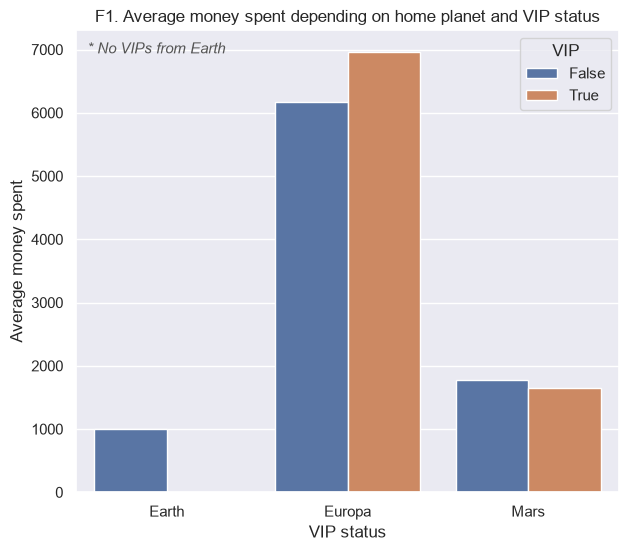

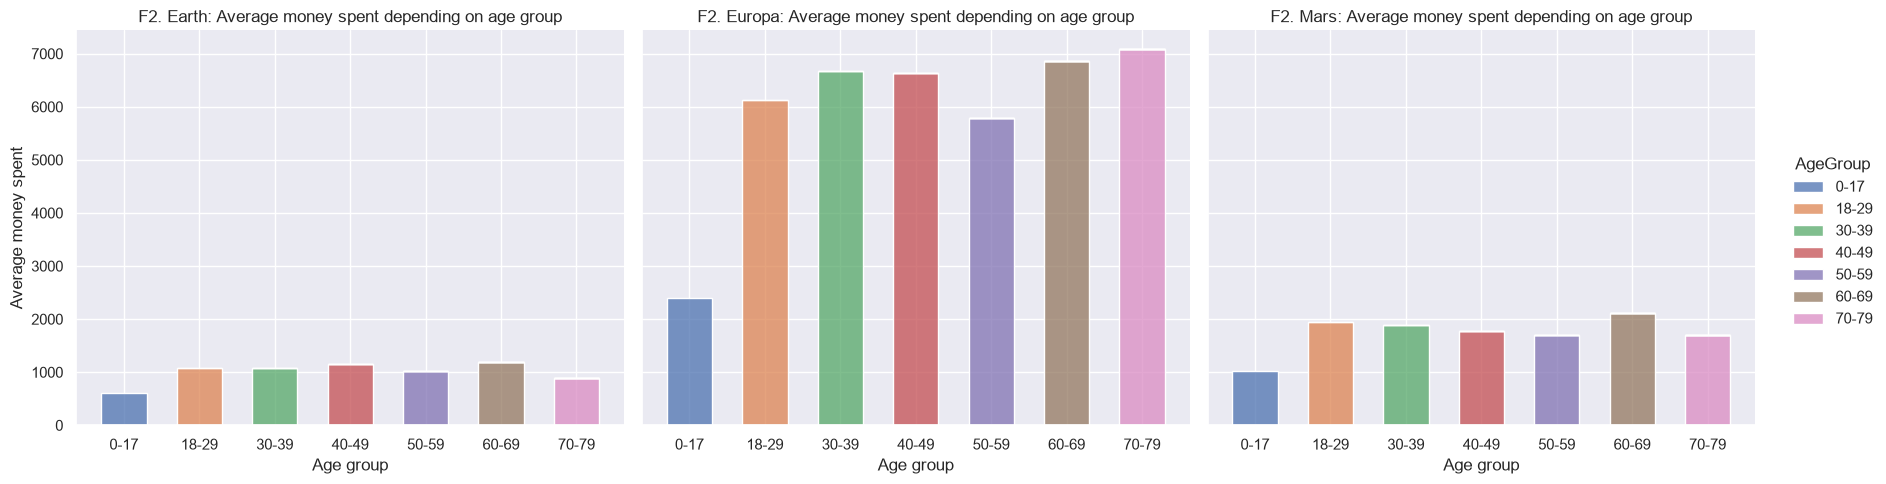

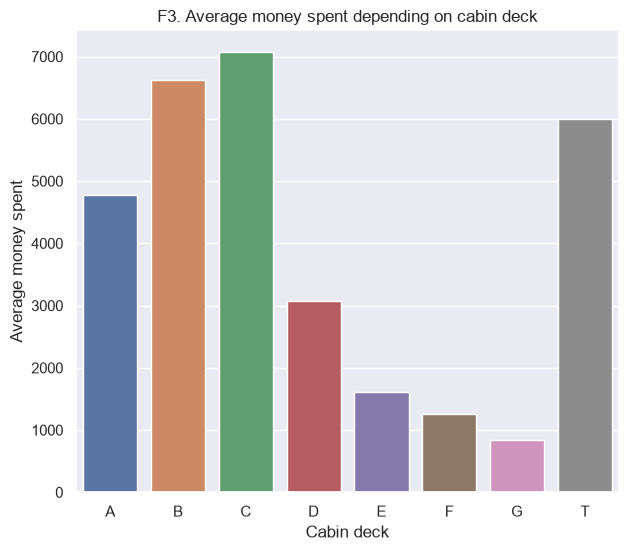

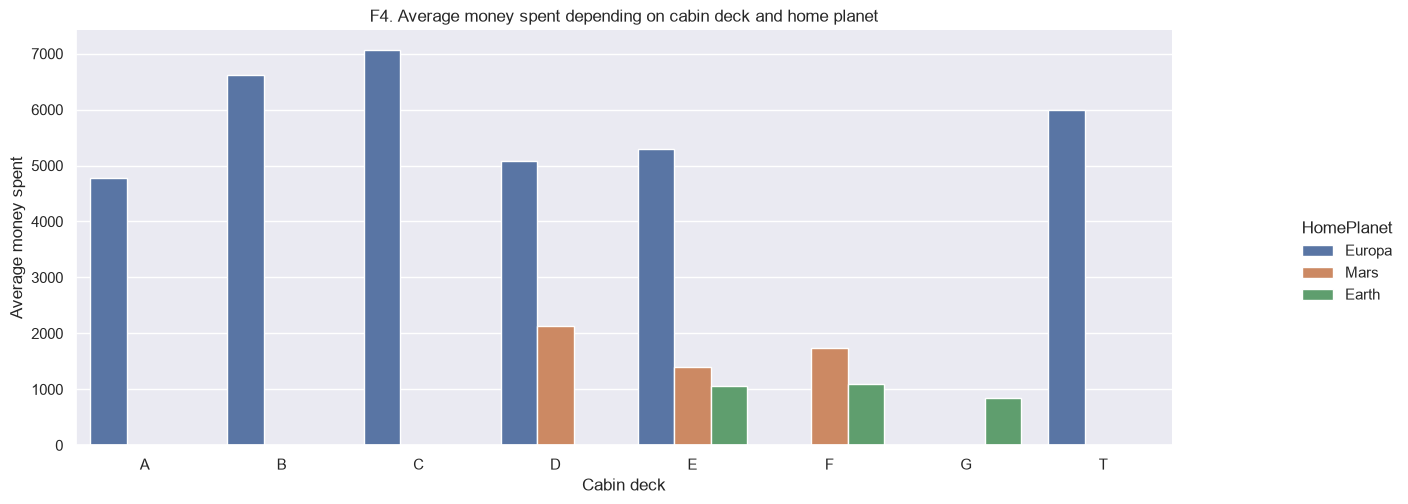

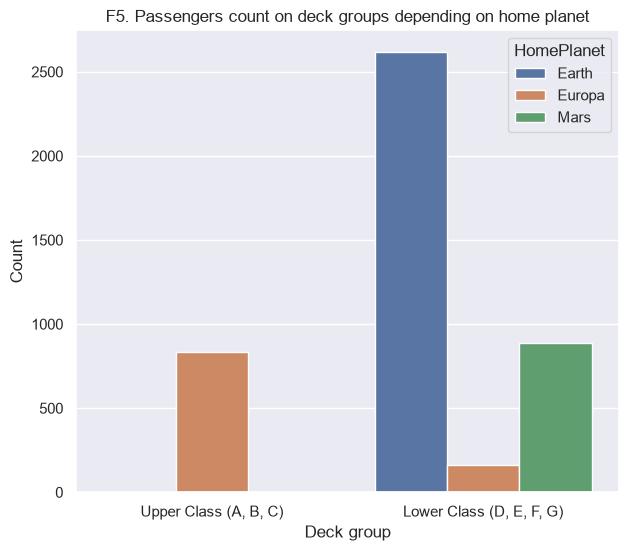

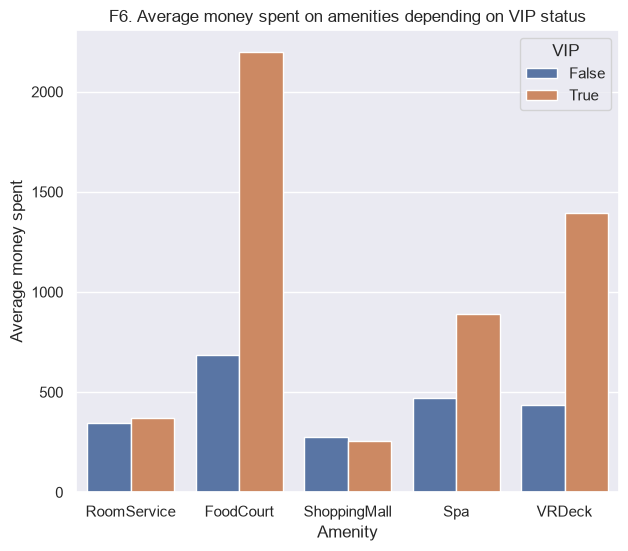

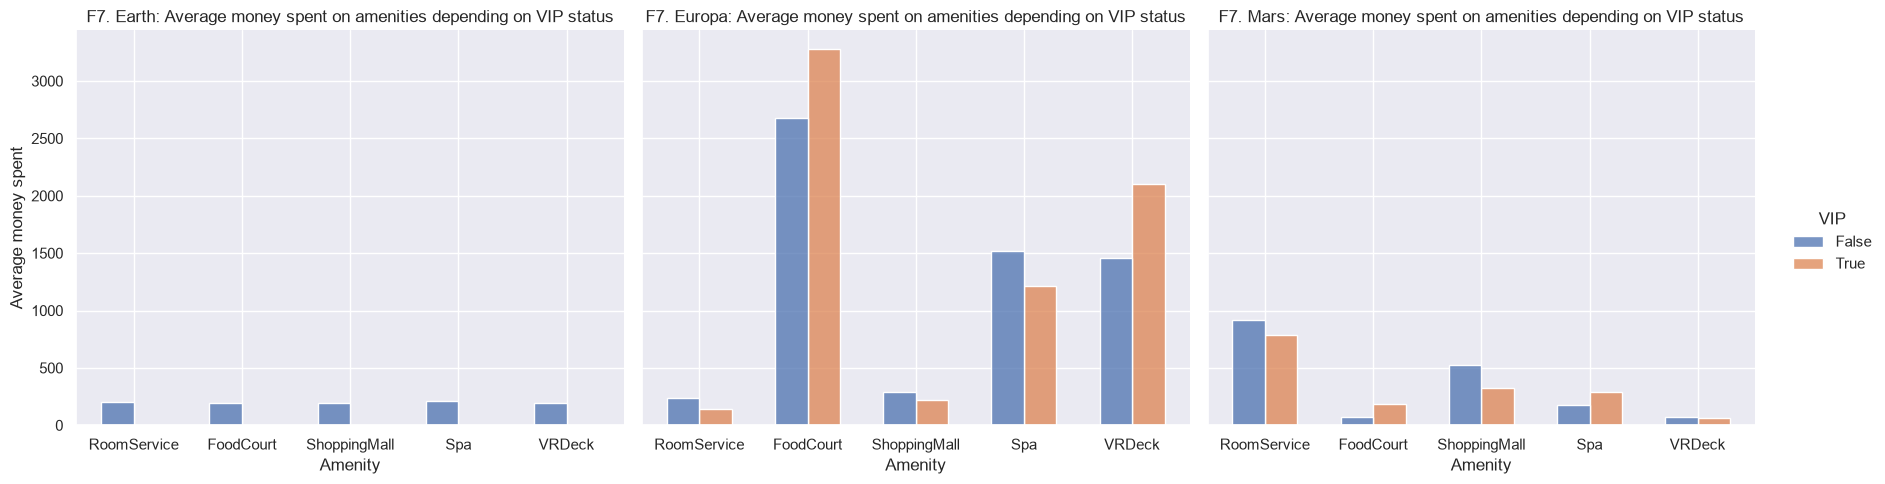

In [61]:
spaceship_titanic_df_f = spaceship_titanic_df[~spaceship_titanic_df[['HomePlanet', 'CryoSleep', 'VIP', 'CabinDeck', 'Total', 'AgeGroup']].isna().any(axis = 1)]
spaceship_titanic_df_f = spaceship_titanic_df_f[spaceship_titanic_df_f.CryoSleep == False]

avgmoneyspent_by_homeplanet_vipstatus = spaceship_titanic_df_f.groupby(['HomePlanet', 'VIP']).agg(
    mean = ('Total', "mean")
)

ax = sns.barplot(
    data = avgmoneyspent_by_homeplanet_vipstatus,
    x = 'HomePlanet',
    hue = 'VIP',
    y = 'mean'
)

plt.text(0.02, 0.95, '* No VIPs from Earth', transform = ax.transAxes, fontsize = 11, color = '#555555', style = 'italic')

plt.title('F1. Average money spent depending on home planet and VIP status')
plt.xlabel('VIP status')
plt.ylabel('Average money spent')

plt.show()

homeplanet_avgmoneyspent_by_agegroup = spaceship_titanic_df_f.groupby(['HomePlanet', 'AgeGroup']).agg(
   count = ('Total', "mean")
)

g = sns.displot(
    data = homeplanet_avgmoneyspent_by_agegroup,
    x = 'AgeGroup',
    hue = 'AgeGroup',
    weights = 'count',
    col = 'HomePlanet',
    multiple = 'stack',
    shrink = 0.6,
    aspect = 1.2
)

g.set_axis_labels('Age group', 'Average money spent')
g.set_titles('F2. {col_name}: Average money spent depending on age group')

plt.show()

avgmoneyspent_by_cabindeck = spaceship_titanic_df_f.groupby('CabinDeck').agg(
    mean = ('Total', "mean")
)

ax = sns.barplot(
    data = avgmoneyspent_by_cabindeck,
    x = 'CabinDeck',
    order = sorted(spaceship_titanic_df['CabinDeck'].dropna().unique()),
    hue = 'CabinDeck',
    y = 'mean'
)

plt.title('F3. Average money spent depending on cabin deck')
plt.xlabel('Cabin deck')
plt.ylabel('Average money spent')

plt.show()

avgmoneyspent_by_cabindeck_homeplanet = spaceship_titanic_df_f.groupby(['CabinDeck', 'HomePlanet']).agg(
    mean = ('Total', "mean")
)

g = sns.catplot(
    data = avgmoneyspent_by_cabindeck_homeplanet,
    kind = 'bar',
    x = 'CabinDeck',
    hue = 'HomePlanet',
    y = 'mean',
    aspect = 2.4
)

sns.move_legend(g, "center left", bbox_to_anchor = (1, 0.5))

plt.title('F4. Average money spent depending on cabin deck and home planet')
plt.xlabel('Cabin deck')
plt.ylabel('Average money spent')

plt.show()

spaceship_titanic_df_f['CabinDeckGroup'] = np.where(
    spaceship_titanic_df_f['CabinDeck'].isin(['A', 'B', 'C']), 
    'ABC', 
    'DEFG'
)

count_by_deckgroup_homeplanet = spaceship_titanic_df_f.groupby(['CabinDeckGroup', 'HomePlanet']).agg(
    count = ('HomePlanet', "count")
)

ax = sns.barplot(
    data = count_by_deckgroup_homeplanet,
    x = 'CabinDeckGroup',
    hue = 'HomePlanet',
    hue_order = sorted(spaceship_titanic_df['HomePlanet'].dropna().unique()),
    y = 'count'
)

plt.title('F5. Passengers count on deck groups depending on home planet')
plt.xlabel('Deck group')
plt.ylabel('Count')

ax.set_xticks(ax.get_xticks())
ax.set_xticklabels(['Upper Class (A, B, C)', 'Lower Class (D, E, F, G)'])

plt.show()

avgmoneyspent_amenities_by_vipstatus = spaceship_titanic_df_f[['VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']].groupby('VIP').mean().reset_index()
avgmoneyspent_amenities_by_vipstatus = avgmoneyspent_amenities_by_vipstatus.melt(
    id_vars = 'VIP',
    var_name = 'Amenity',
    value_name = 'mean'
)

ax = sns.barplot(
    data = avgmoneyspent_amenities_by_vipstatus,
    x = 'Amenity',
    hue = 'VIP',
    y = 'mean'
)

plt.title('F6. Average money spent on amenities depending on VIP status')
plt.xlabel('Amenity')
plt.ylabel('Average money spent')

plt.show()

homeplanet_avgmoneyspent_amienities_by_vipstatus = spaceship_titanic_df_f[['HomePlanet', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']].groupby(['HomePlanet', 'VIP']).mean().reset_index()

homeplanet_avgmoneyspent_amienities_by_vipstatus = homeplanet_avgmoneyspent_amienities_by_vipstatus.melt(
    id_vars = ['HomePlanet', 'VIP'],
    var_name = 'Amenity',
    value_name = 'mean'
)

g = sns.displot(
    data = homeplanet_avgmoneyspent_amienities_by_vipstatus,
    x = 'Amenity',
    hue = 'VIP',
    weights = 'mean',
    col = 'HomePlanet',
    multiple = 'dodge',
    shrink = 0.6,
    aspect = 1.2
)

g.set_axis_labels('Amenity', 'Average money spent')
g.set_titles('F7. {col_name}: Average money spent on amenities depending on VIP status')

plt.show()

<span style = "font-size: 20px; color: green;">How much money passengers spend on amenities?</span>

* Passengers from Europa spend most (more than 6000 on average)
* VIPs and non-VIPs spend around the same amount of money<br><br>

* Passengers from different age groups spend around the same amount of money (around average money spent for given planets) except for children who spend less than other age groups<br><br>

* Passengers from decks A, B, C spend most (as expected because they are only from Europa)
* Passengers from deck G spend least, then passengers from decks F, E and D respectively
(as expected because on deck G live only passengers from Earth, on deck F there is less passengers from Earth and more from Mars, ...)<br><br>

* Passengers from Europa spend most on decks B and C (~6500 and ~7000 on average respectively), then on decks A, D and E they spend ~5000 on average
* Passengers from Mars spend most on deck D (~2100 on average) and least on deck E (~1400 on average)
* Passengers from Earth spend around the same on every deck (~1000 on average)<br><br>

* Based on where passengers on different decks are from and how much they spend, we can divide passengers from decks A, B and C as upper class and passengers from decks D, E, F and G as lower class<br><br>

* It could seem that VIPs spend 3x more on food court, 2x more on spa and 3x more on VR deck than non-VIPs, but
looking at average money spent on amenities on different planets, these values are more similar to each other

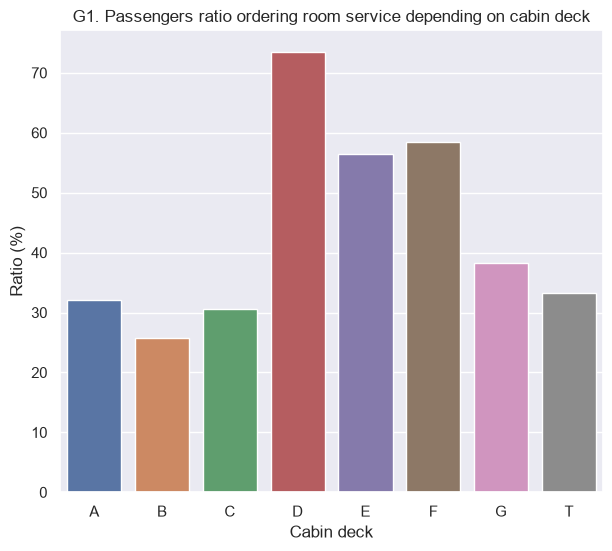

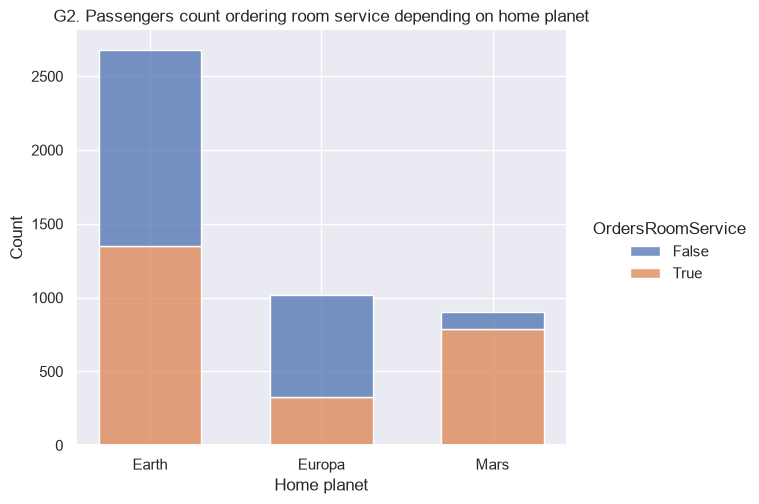

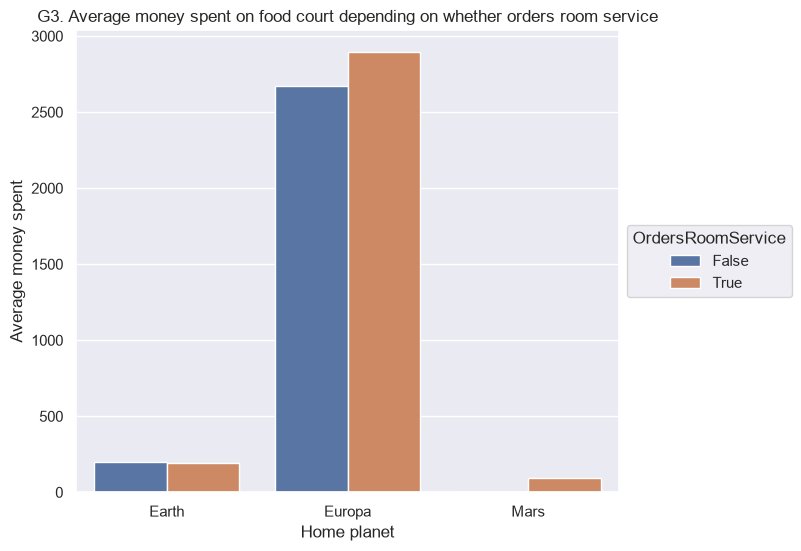

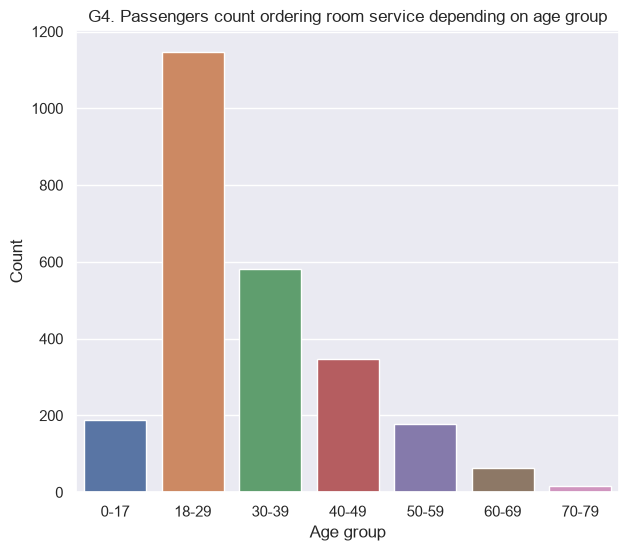

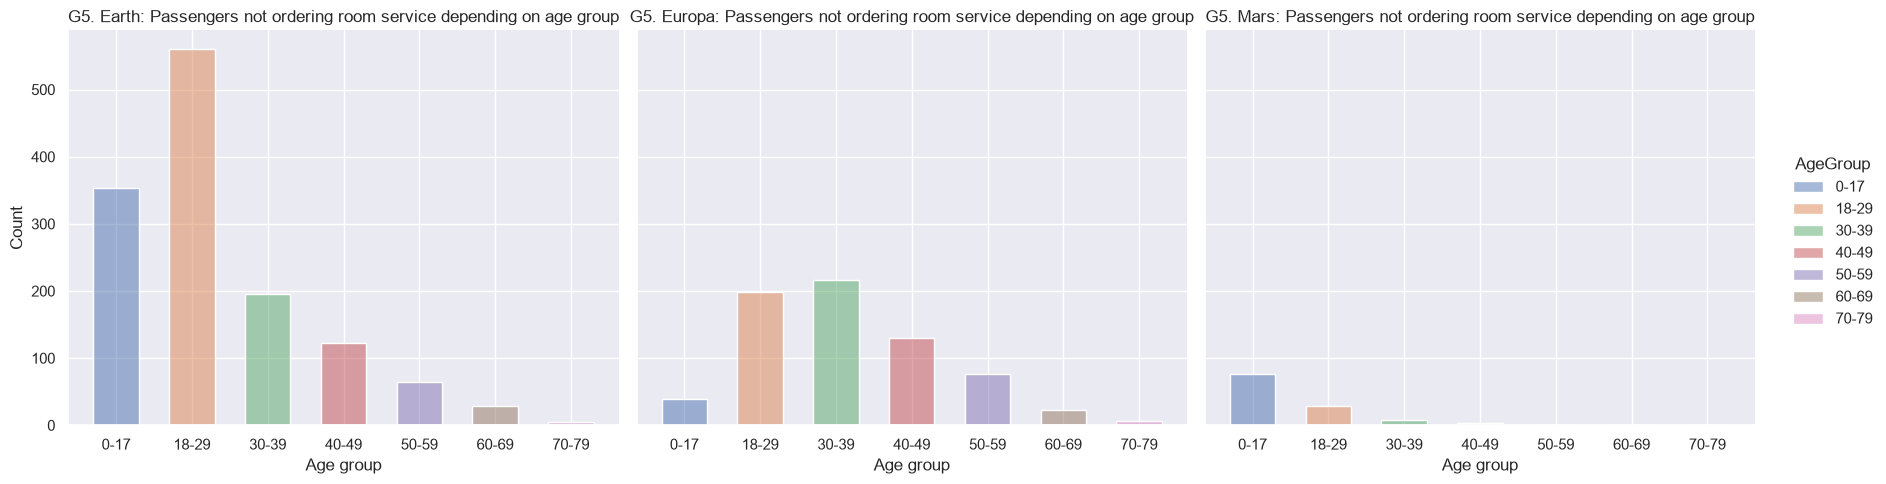

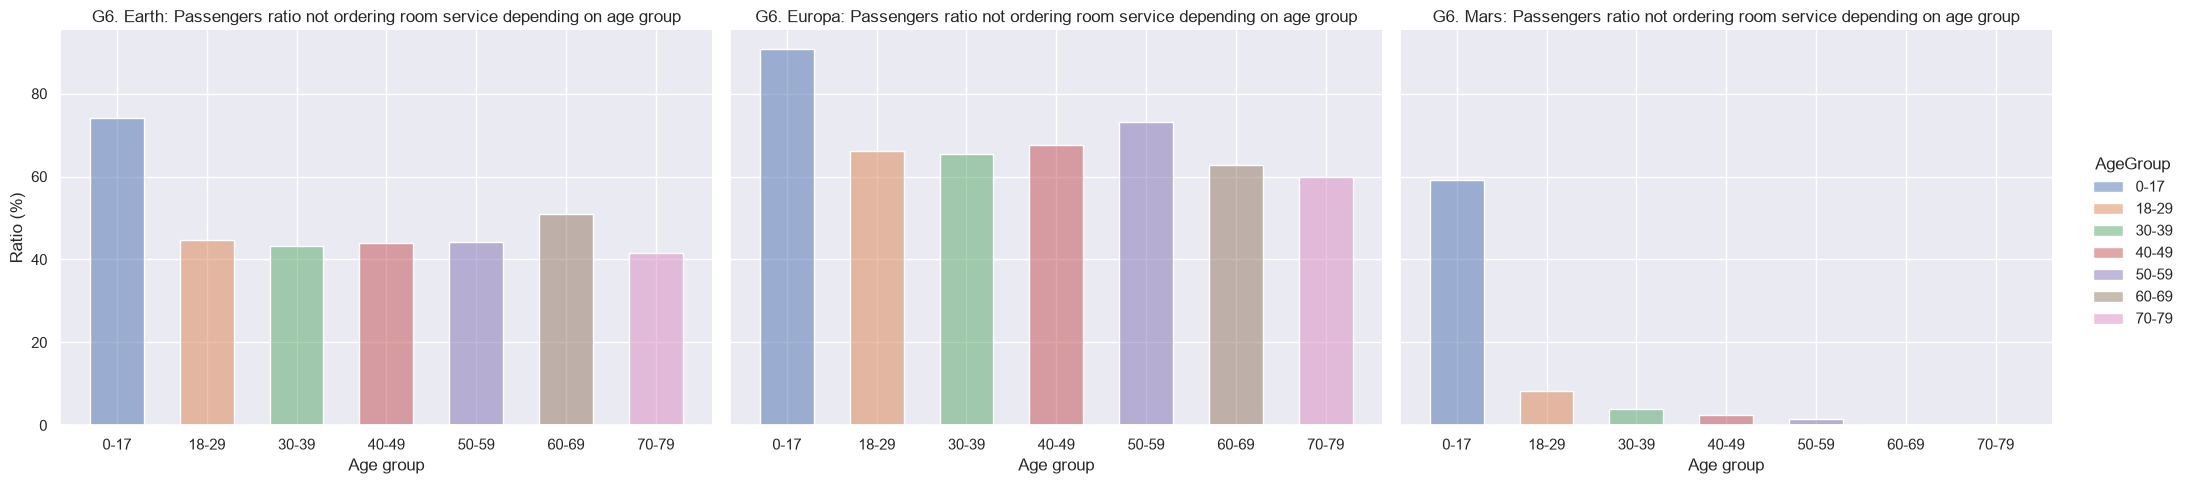

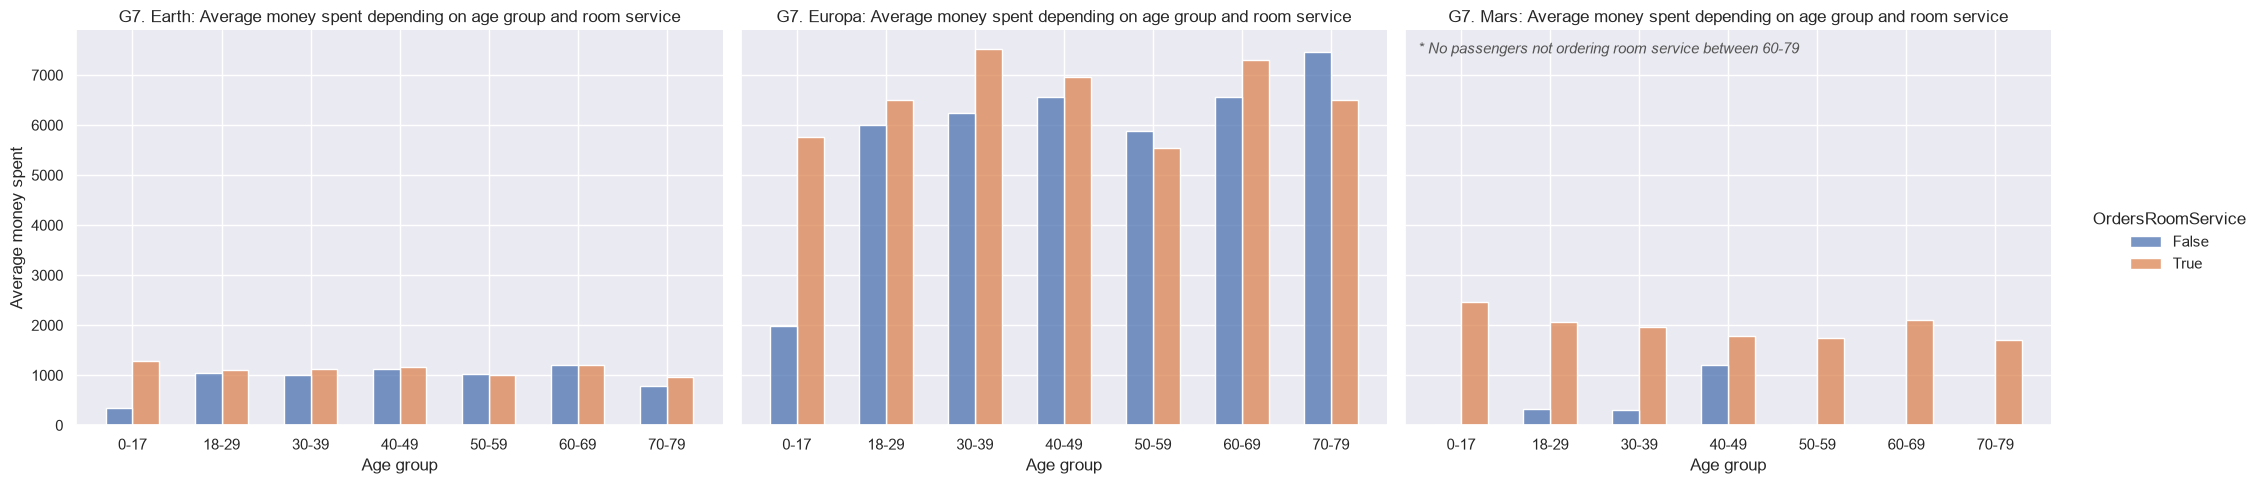

In [62]:
spaceship_titanic_df_g = spaceship_titanic_df[~spaceship_titanic_df[['CryoSleep', 'Age', 'Total', 'CabinDeck']].isna().any(axis = 1)]
spaceship_titanic_df_g = spaceship_titanic_df_g[spaceship_titanic_df_g.CryoSleep == False]

spaceship_titanic_df_g['OrdersRoomService'] = spaceship_titanic_df_g.RoomService > 0

ratio_orderingroomservice_by_cabindeck = spaceship_titanic_df_g[spaceship_titanic_df_g.RoomService > 0].groupby('CabinDeck').agg(
    ratio = ('RoomService', "count"),
    mean = ('RoomService', "mean")
)

temp_count_by_cabindeck_cryosleep = count_by_cabindeck_cryosleep.reset_index().set_index('CabinDeck')

ratio_orderingroomservice_by_cabindeck['ratio'] = ratio_orderingroomservice_by_cabindeck['ratio'] / temp_count_by_cabindeck_cryosleep.loc[temp_count_by_cabindeck_cryosleep.CryoSleep == False, 'count'] * 100

ax = sns.barplot(
    data = ratio_orderingroomservice_by_cabindeck,
    x = 'CabinDeck',
    hue = 'CabinDeck',
    y = 'ratio'
)

plt.title('G1. Passengers ratio ordering room service depending on cabin deck')
plt.xlabel('Cabin deck')
plt.ylabel('Ratio (%)')

plt.show()

count_orderingroomservice_by_homeplanet = spaceship_titanic_df_g.groupby(['HomePlanet', 'OrdersRoomService']).agg(
    count = ('OrdersRoomService', "count"),
    mean = ('Total', "mean")
)

g = sns.displot(
    data = count_orderingroomservice_by_homeplanet,
    x = 'HomePlanet',
    hue = 'OrdersRoomService',
    weights = 'count',
    multiple = 'stack',
    shrink = 0.6,
    aspect = 1.2
)

g.set_axis_labels('Home planet', 'Count')
plt.title('G2. Passengers count ordering room service depending on home planet')

plt.show()

avgmoneyspent_foodcourt_by_ordersroomservice = spaceship_titanic_df_g.groupby(['HomePlanet', 'OrdersRoomService']).agg(
    mean = ('FoodCourt', "mean")
)

ax = sns.barplot(
    data = avgmoneyspent_foodcourt_by_ordersroomservice,
    x = 'HomePlanet',
    hue = 'OrdersRoomService',
    y = 'mean'
)

sns.move_legend(ax, "center left", bbox_to_anchor = (1, 0.5))

plt.title('G3. Average money spent on food court depending on whether orders room service')
plt.xlabel('Home planet')
plt.ylabel('Average money spent')

plt.show()

count_orderingroomservice_by_agegroup = spaceship_titanic_df_g[spaceship_titanic_df_g.OrdersRoomService == True].groupby('AgeGroup').agg(
    count = ('AgeGroup', "count")
)

ax = sns.barplot(
    data = count_orderingroomservice_by_agegroup,
    x = 'AgeGroup',
    hue = 'AgeGroup',
    y = 'count',
    dodge = False
)

plt.title('G4. Passengers count ordering room service depending on age group')
plt.xlabel('Age group')
plt.ylabel('Count')

plt.show()

pom_homeplanet_count_notorderingroomservice_by_agegroup = spaceship_titanic_df_g.groupby(['HomePlanet', 'AgeGroup']).agg(
    pom_count = ('AgeGroup', "count")
)

homeplanet_count_notorderingroomservice_by_agegroup = spaceship_titanic_df_g[spaceship_titanic_df_g.OrdersRoomService == False].groupby(['HomePlanet', 'AgeGroup']).agg(
    count = ('AgeGroup', "count")
)

homeplanet_count_notorderingroomservice_by_agegroup = homeplanet_count_notorderingroomservice_by_agegroup.merge(pom_homeplanet_count_notorderingroomservice_by_agegroup, on = ['HomePlanet', 'AgeGroup'], how = 'left')
homeplanet_count_notorderingroomservice_by_agegroup['ratio'] = homeplanet_count_notorderingroomservice_by_agegroup['count'] / homeplanet_count_notorderingroomservice_by_agegroup['pom_count'] * 100

g = sns.displot(
    data = homeplanet_count_notorderingroomservice_by_agegroup,
    x = 'AgeGroup',
    hue = 'AgeGroup',
    weights = 'count',
    col = 'HomePlanet',
    shrink = 0.6,
    aspect = 1.2
)

g.set_axis_labels('Age group', 'Count')
g.set_titles('G5. {col_name}: Passengers not ordering room service depending on age group')

plt.show()

g = sns.displot(
    data = homeplanet_count_notorderingroomservice_by_agegroup,
    x = 'AgeGroup',
    hue = 'AgeGroup',
    weights = 'ratio',
    col = 'HomePlanet',
    shrink = 0.6,
    aspect = 1.4
)

g.set_axis_labels('Age group', 'Ratio (%)')
g.set_titles('G6. {col_name}: Passengers ratio not ordering room service depending on age group')

plt.show()

homeplanet_avgmoneyspent_by_agegroup_ordersroomservice = spaceship_titanic_df_g.groupby(['HomePlanet', 'AgeGroup', 'OrdersRoomService']).agg(
    mean = ('Total', "mean")
)

g = sns.displot(
    data = homeplanet_avgmoneyspent_by_agegroup_ordersroomservice,
    x = 'AgeGroup',
    hue = 'OrdersRoomService',
    weights = 'mean',
    col = 'HomePlanet',
    multiple = 'dodge',
    shrink = 0.6,
    aspect = 1.4
)

g.set_axis_labels('Age group', 'Average money spent')
g.set_titles('G7. {col_name}: Average money spent depending on age group and room service')

g.axes.flatten()[2].text(
    x = 0.02,
    y = 0.97,
    s = "* No passengers not ordering room service between 60-79",
    ha = "left",
    va = 'top',
    transform = g.axes.flatten()[2].transAxes,
    fontsize = 11, color = '#555555', style = 'italic'
)

plt.show()

<span style = "font-size: 20px; color: green;">Which passengers order room service the most?<span />

* Passengers from decks A, B and C order room service much less than passengers from decks D, E and F<br><br>

* Only ~33% of passengers from Europa order room service although they spend most
* Almost every passenger from Mars orders room service (~85%)

<span style = "font-size: 20px; color: green;">Which passengers spend the most on room service?<span />
    
* Passengers from Mars spend ~4x more on room service than passengers from other planets (800-900 compared to ~250 spent by passengers from Europa and ~200 spent by passengers from Earth)<br><br>

* Passengers ordering room service tend to spend more than the ones not ordering room service
* On Mars the difference is the most visible (passengers ordering room service spend ~2000 and passengers not ordering room service spend ~100 on average)<br><br>

* Passengers ordering room service still spend around the same or more on food court than the ones not ordering room service
* Passengers from Mars not ordering room service spend almost nothing on food court

<span style = "font-size: 20px; color: green;">How old are passengers ordering room service?<span />

* ~70% of all passengers ordering room service are between 18-39<br><br>

* On every planet percentage of children not ordering room service is much higher than in any other age groups
* On Earth and Europa average money spent by age groups is around the same between passengers ordering room service and not ordering room service except for children
* Children not ordering room service spend much less than children ordering room service
* On Mars the difference between average money spent by passengers ordering room service and not ordering room service is clearly visible in almost every age group<br><br>

* Such low average money spent by passengers from Mars not ordering room service is caused because mostly children do not order room service and their average money spent is 0

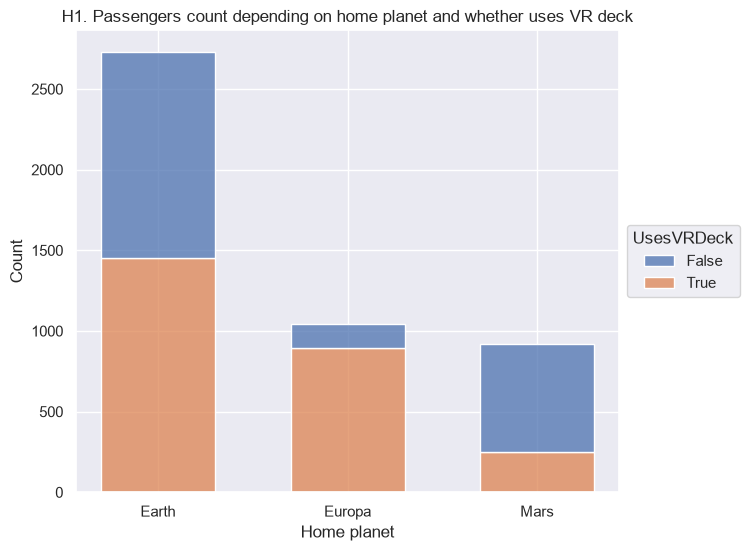

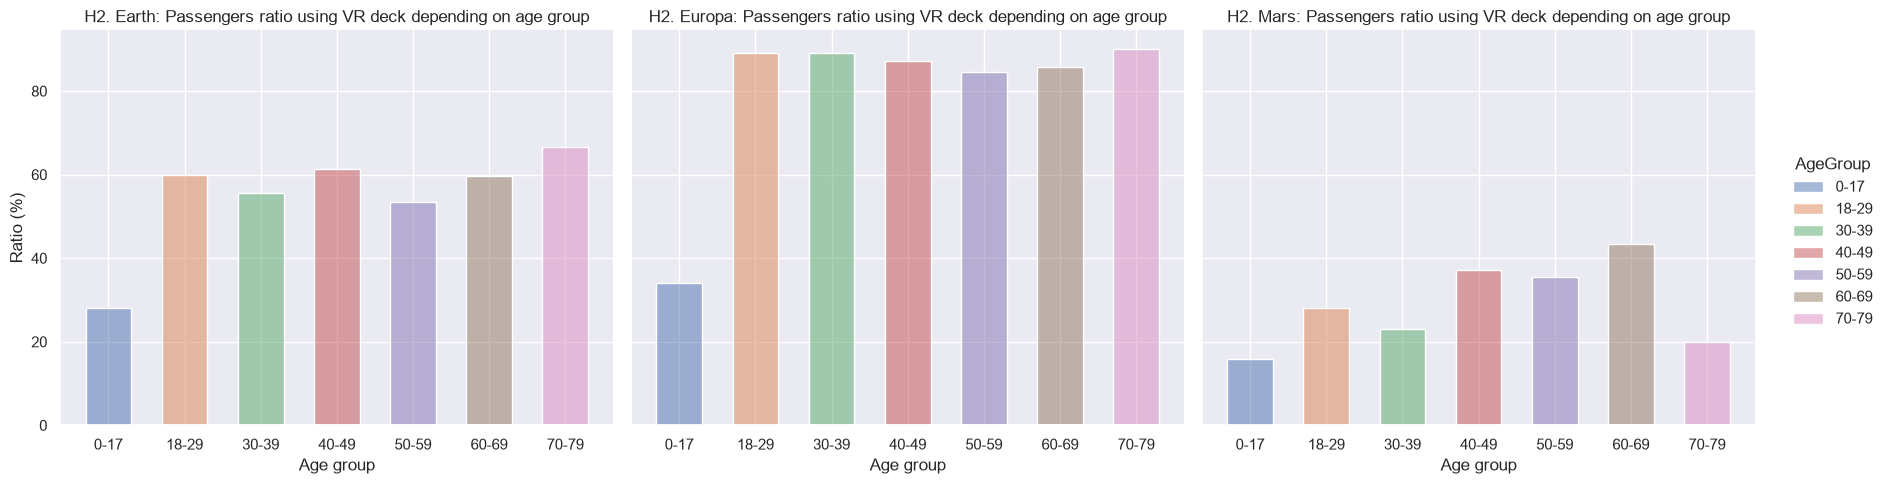

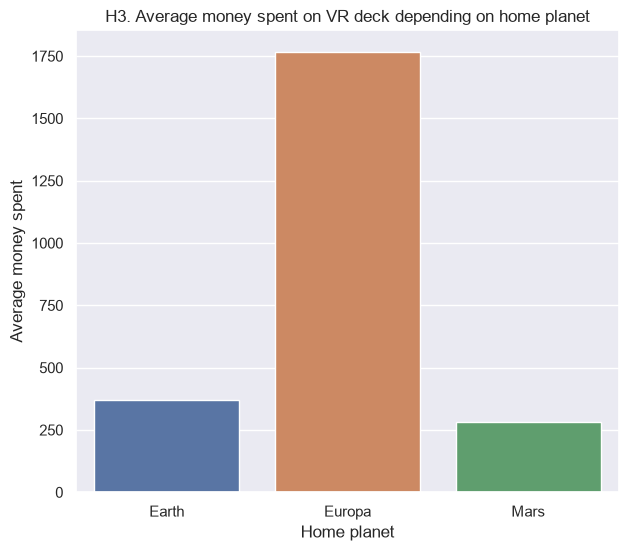

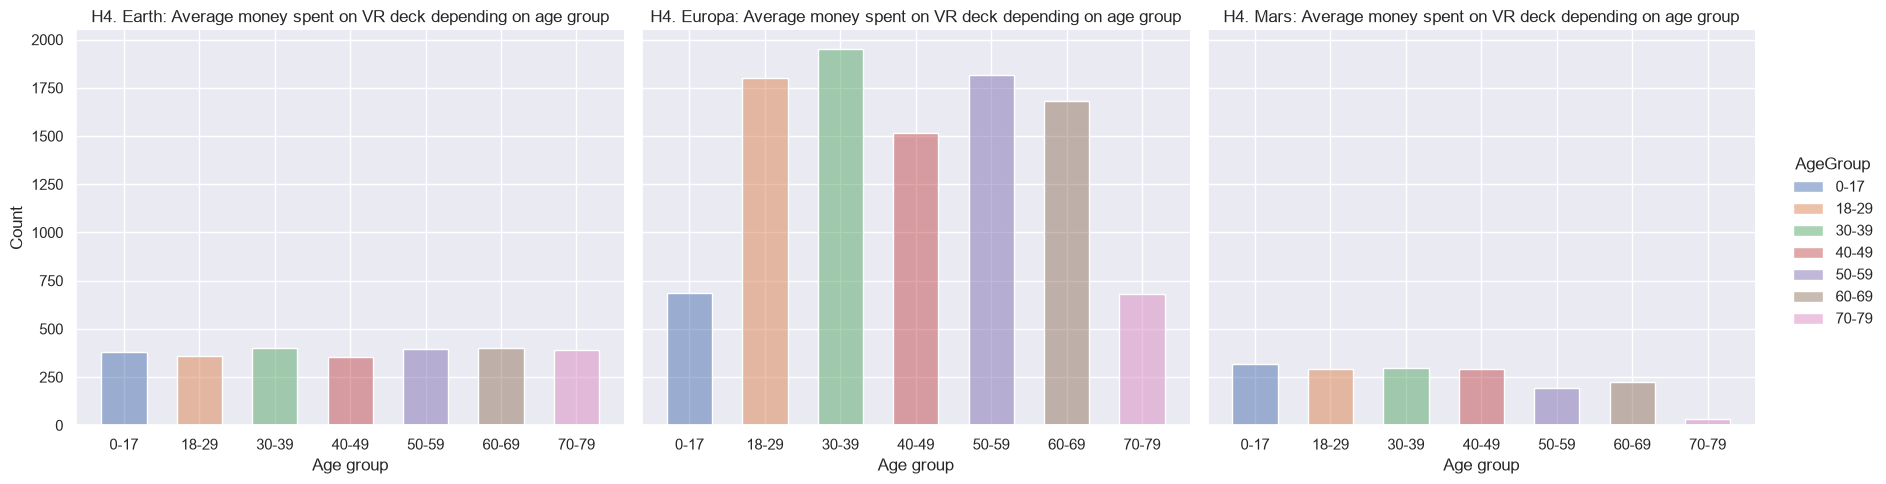

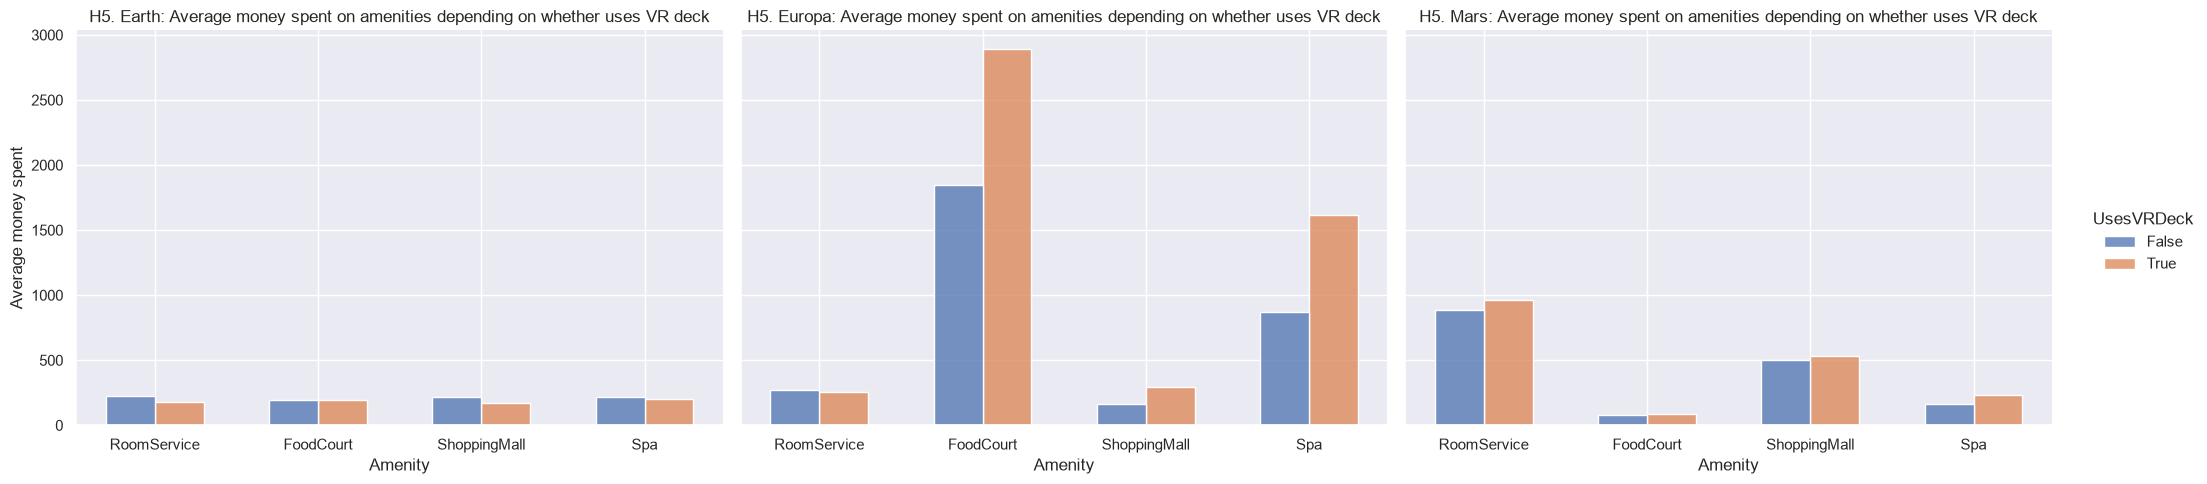

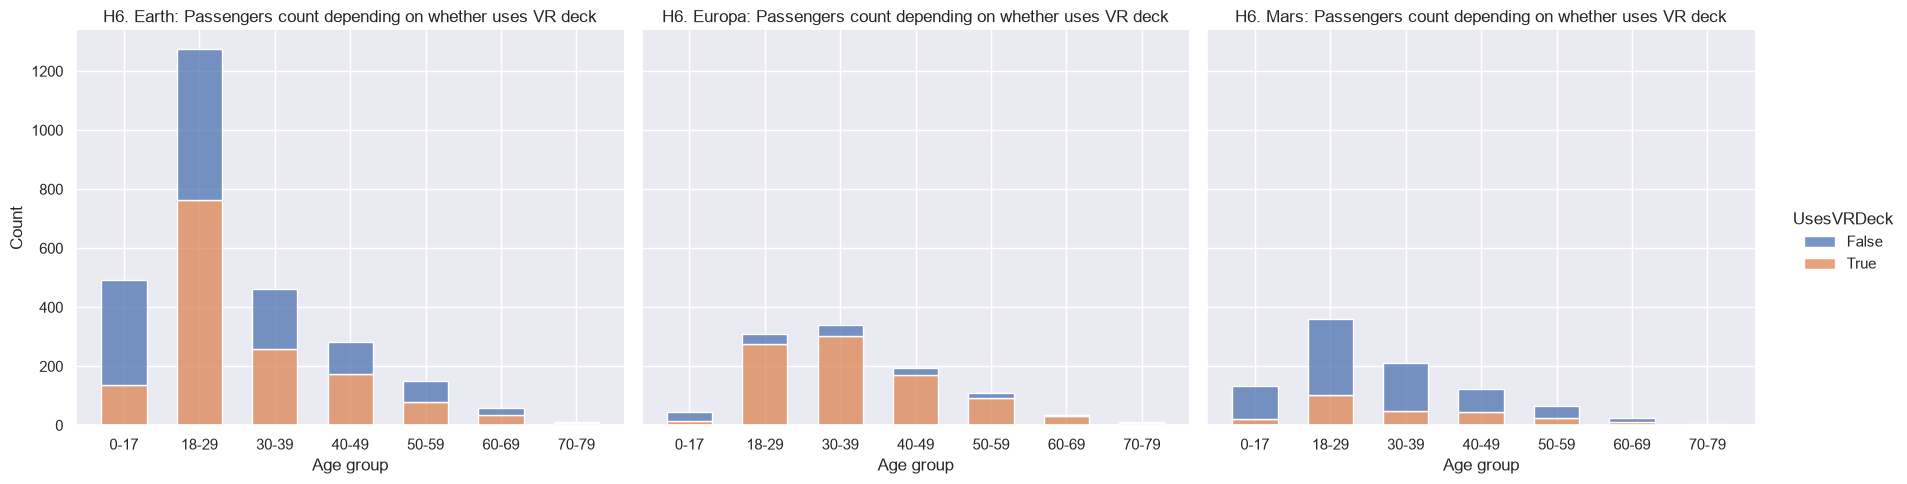

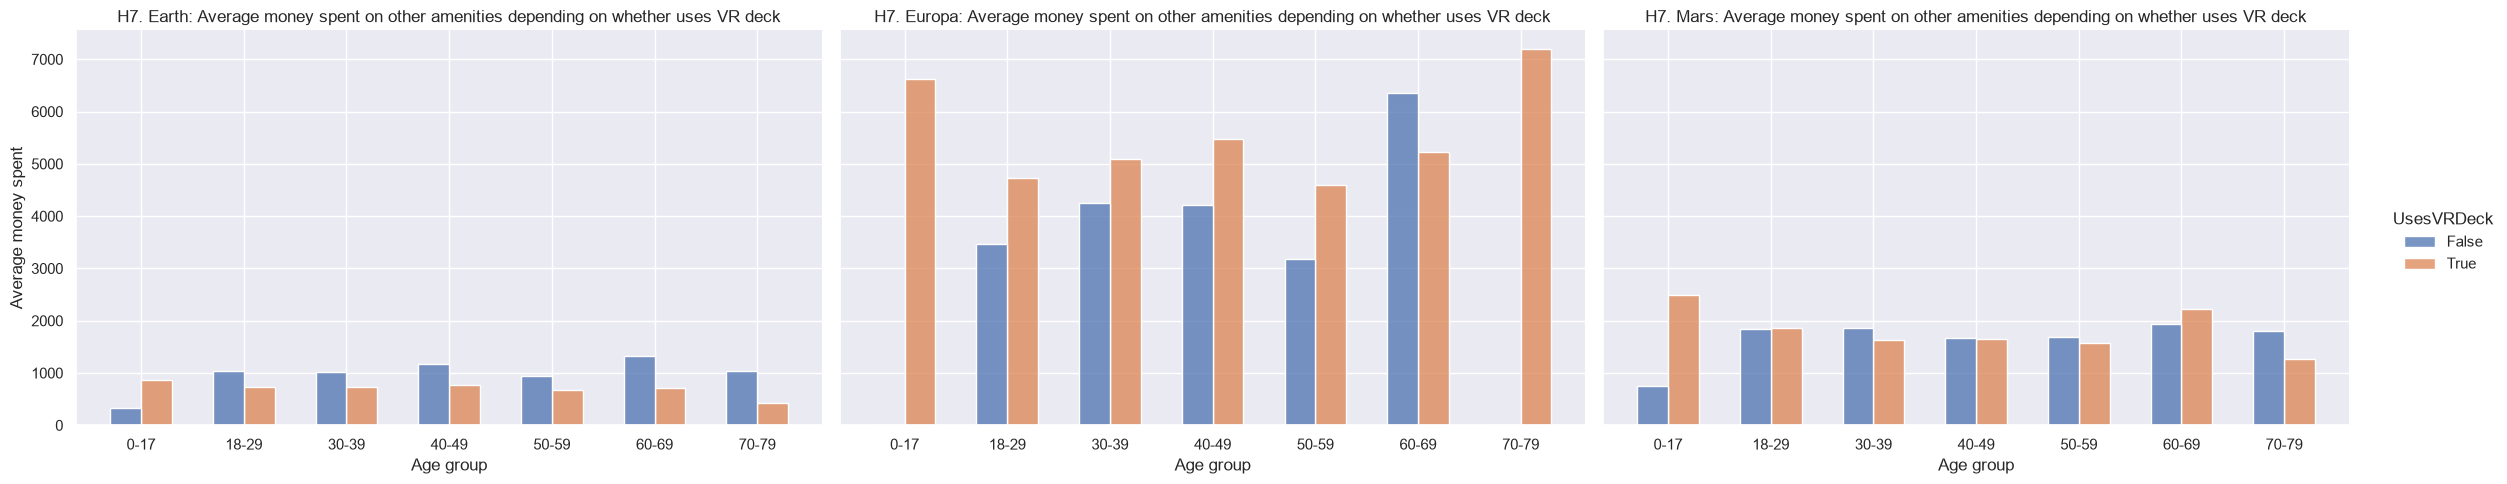

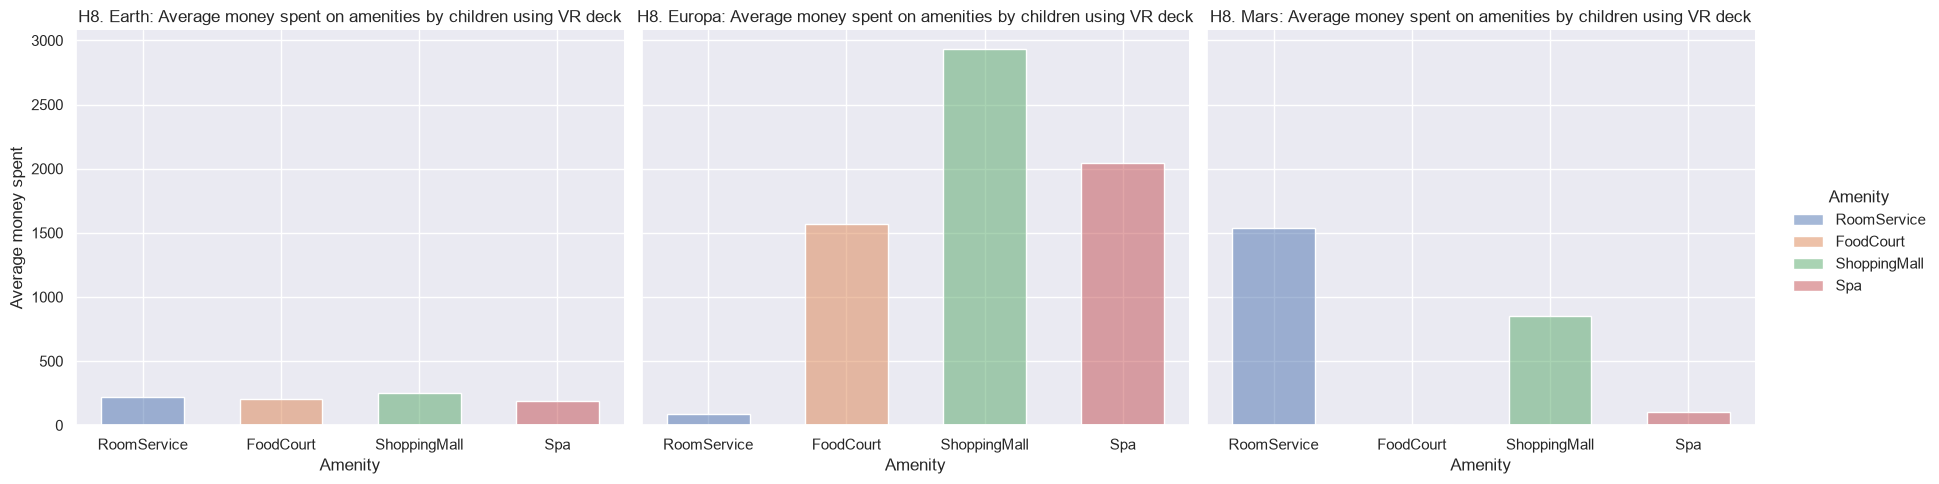

In [63]:
spaceship_titanic_df_h = spaceship_titanic_df[~spaceship_titanic_df[['HomePlanet', 'CryoSleep', 'AgeGroup', 'Total']].isna().any(axis = 1)]
spaceship_titanic_df_h = spaceship_titanic_df_h[(spaceship_titanic_df_h.CryoSleep == False)]

spaceship_titanic_df_h['UsesVRDeck'] = spaceship_titanic_df_h['VRDeck'] > 0

spaceship_titanic_df_h_2 = spaceship_titanic_df_h[spaceship_titanic_df_h.VRDeck > 0]

count_by_homeplanet_usesvrdeck = spaceship_titanic_df_h.groupby(['HomePlanet', 'UsesVRDeck']).agg(
    count = ('UsesVRDeck', "count")
)

ax = sns.histplot(
    data = count_by_homeplanet_usesvrdeck,
    x = 'HomePlanet',
    hue = 'UsesVRDeck',
    weights = 'count',
    multiple = 'stack',
    shrink = 0.6
)

sns.move_legend(ax, "center left", bbox_to_anchor = (1, 0.5))

plt.title('H1. Passengers count depending on home planet and whether uses VR deck')
plt.xlabel('Home planet')
plt.ylabel('Count')

plt.show()

avgmoneyspent_vrdeck_by_homeplanet = spaceship_titanic_df_h_2.groupby(['HomePlanet']).agg(
    mean = ('VRDeck', "mean")
)

pom_ratio_avgmoneyspent_vrdeck_by_agegroup = spaceship_titanic_df_h.groupby(['HomePlanet', 'AgeGroup']).agg(
    pom_count = ('AgeGroup', "count")
)

ratio_avgmoneyspent_vrdeck_by_agegroup = spaceship_titanic_df_h_2.groupby(['HomePlanet', 'AgeGroup']).agg(
    ratio = ('AgeGroup', "count"),
    mean = ('VRDeck', "mean")
)

ratio_avgmoneyspent_vrdeck_by_agegroup = ratio_avgmoneyspent_vrdeck_by_agegroup.merge(pom_ratio_avgmoneyspent_vrdeck_by_agegroup, on = ['HomePlanet', 'AgeGroup'], how = 'left')
ratio_avgmoneyspent_vrdeck_by_agegroup['ratio'] = ratio_avgmoneyspent_vrdeck_by_agegroup['ratio'] / ratio_avgmoneyspent_vrdeck_by_agegroup['pom_count'] * 100

for prop in ['ratio', '', 'mean']:
    if prop == '':
        ax = sns.barplot(
            data = avgmoneyspent_vrdeck_by_homeplanet,
            x = 'HomePlanet',
            hue = 'HomePlanet',
            y = 'mean'
        )
        
        plt.title('H3. Average money spent on VR deck depending on home planet')
        plt.xlabel('Home planet')
        plt.ylabel('Average money spent')
        
        plt.show()

        continue
    
    g = sns.displot(
        data = ratio_avgmoneyspent_vrdeck_by_agegroup,
        x = 'AgeGroup',
        hue = 'AgeGroup',
        weights = prop,
        col = 'HomePlanet',
        shrink = 0.6,
        aspect = 1.2
    )

    g.set_axis_labels('Age group', 'Ratio (%)' if prop == 'ratio' else 'Count')
    g.set_titles('H2. {col_name}: Passengers ratio using VR deck depending on age group' if prop == 'ratio' else 'H4. {col_name}: Average money spent on VR deck depending on age group')
    
    plt.show()

homeplanet_avgmoneyspent_amenities_by_usesvrdeck = spaceship_titanic_df_h[['HomePlanet', 'UsesVRDeck', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa']].groupby(['HomePlanet', 'UsesVRDeck']).mean().reset_index()
homeplanet_avgmoneyspent_amenities_by_usesvrdeck = homeplanet_avgmoneyspent_amenities_by_usesvrdeck.melt(
    id_vars = ['HomePlanet', 'UsesVRDeck'],
    var_name = 'Amenity',
    value_name = 'mean'
)

g = sns.displot(
    data = homeplanet_avgmoneyspent_amenities_by_usesvrdeck,
    x = 'Amenity',
    hue = 'UsesVRDeck',
    weights = 'mean',
    col = 'HomePlanet',
    multiple = 'dodge',
    shrink = 0.6,
    aspect = 1.4
)

g.set_axis_labels('Amenity', 'Average money spent')
g.set_titles('H5. {col_name}: Average money spent on amenities depending on whether uses VR deck')

plt.show()

homeplanet_count_by_usesvrdeck = spaceship_titanic_df_h.groupby(['HomePlanet', 'AgeGroup', 'UsesVRDeck']).agg(
    count = ('UsesVRDeck', "count")
)

g = sns.displot(
    data = homeplanet_count_by_usesvrdeck,
    x = 'AgeGroup',
    hue = 'UsesVRDeck',
    weights = 'count',
    col = 'HomePlanet',
    multiple = 'stack',
    shrink = 0.6,
    aspect = 1.2
)

g.set_axis_labels('Age group', 'Count')
g.set_titles('H6. {col_name}: Passengers count depending on whether uses VR deck')

plt.show()

homeplanet_avgmoneyspent_otheramenities_by_agegroup_usesvrdeck = spaceship_titanic_df_h.groupby(['HomePlanet', 'AgeGroup', 'UsesVRDeck']).agg(
    mean_2 = ('Total', "mean")
).reset_index().set_index(['HomePlanet', 'AgeGroup'])

homeplanet_avgmoneyspent_otheramenities_by_agegroup_usesvrdeck = homeplanet_avgmoneyspent_otheramenities_by_agegroup_usesvrdeck.merge(ratio_avgmoneyspent_vrdeck_by_agegroup[['mean']], on = ['HomePlanet', 'AgeGroup'], how = 'left')
homeplanet_avgmoneyspent_otheramenities_by_agegroup_usesvrdeck.loc[homeplanet_avgmoneyspent_otheramenities_by_agegroup_usesvrdeck.UsesVRDeck == False, 'mean'] = 0
homeplanet_avgmoneyspent_otheramenities_by_agegroup_usesvrdeck['mean_2'] -= homeplanet_avgmoneyspent_otheramenities_by_agegroup_usesvrdeck['mean']

g = sns.displot(
    data = homeplanet_avgmoneyspent_otheramenities_by_agegroup_usesvrdeck,
    x = 'AgeGroup',
    hue = 'UsesVRDeck',
    weights = 'mean_2',
    col = 'HomePlanet',
    multiple = 'dodge',
    shrink = 0.6,
    aspect = 1.6
)

g.set_axis_labels('Age group', 'Average money spent')
g.set_titles('H7. {col_name}: Average money spent on other amenities depending on whether uses VR deck')

plt.show()

homeplanet_avgmoneyspent_amenities_children_usingvrdeck = spaceship_titanic_df_h[(spaceship_titanic_df_h.UsesVRDeck == True) & (spaceship_titanic_df_h.AgeGroup == '0-17')].groupby('HomePlanet')[['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa']].mean().reset_index()
homeplanet_avgmoneyspent_amenities_children_usingvrdeck = homeplanet_avgmoneyspent_amenities_children_usingvrdeck.melt(
    id_vars = ['HomePlanet'],
    var_name = 'Amenity',
    value_name = 'mean'
)

g = sns.displot(
    data = homeplanet_avgmoneyspent_amenities_children_usingvrdeck,
    x = 'Amenity',
    hue = 'Amenity',
    weights = 'mean',
    col = 'HomePlanet',
    shrink = 0.6,
    aspect = 1.2
)

g.set_axis_labels('Amenity', 'Average money spent')
g.set_titles('H8. {col_name}: Average money spent on amenities by children using VR deck')

plt.show()

<span style = "font-size: 20px; color: green;">Which passengers use VR deck the most?<span />

* Passengers from Europa use VR deck most (~85%) and passengers from Mars use VR deck least (~25%)<br><br>

* On Earth and Europa percentage of passengers from different age groups using VR deck is around the same except for children who use VR deck much less
* On Mars values vary more from ~20% to ~40% of passengers using VR deck depending on age group

<span style = "font-size: 20px; color: green;">Which passengers spend the most on VR deck?<span />

* On average passengers from Europa spend much more on VR deck (~1750) than passengers from other planets<br><br>

* On Earth average money spent on VR deck by passengers from different age groups is around the same
* On Mars passengers between 70-79 years old spend much less on VR deck than other age groups
* On Europa children and passengers between 70-79 years old spend much less on VR deck than other age groups<br><br>

* On Earth and Mars average money spent on amenities is around the same between passengers using VR deck and passengers not using VR deck
* Passengers from Europa using VR deck spend much more on food court and spa than passengers not using VR deck<br><br>

* On every planet children not using VR deck spend much less on other amenities than children using VR deck
* Especially for Europa and Mars children lower average money spent on different amenities by passengers not using VR deck<br><br>

* On Earth passengers not using VR deck spend more on other amenities except for children<br><br>

* On Europa children and passengers between 70-79 years old not using VR deck spend almost nothing on amenities
* ~20% of passengers from Europa not using VR deck are children<br><br>

* From passengers from different planets using VR deck children spend the most on other amenities<br><br>

* These children from Europa spend less on food court (~1500 compared to more than 2500) but spend much more on shopping mall (almost 3000 compared to less than 500) and spa (~2000 compared to less than 1500)
* These children from Mars spend more on room service (~1500 compared to less than 1000) and shopping mall (~800 compared to ~500) but spend almost nothing on food court<br><br>

<span style = "font-size: 30px; color: green;">Which passengers are transported to another dimension?</span>

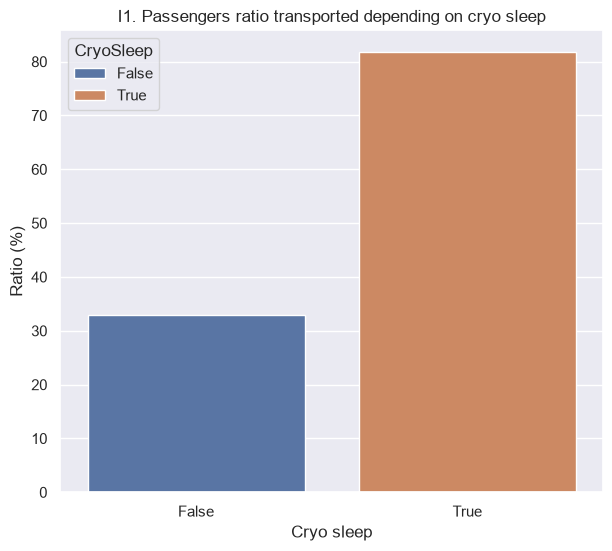

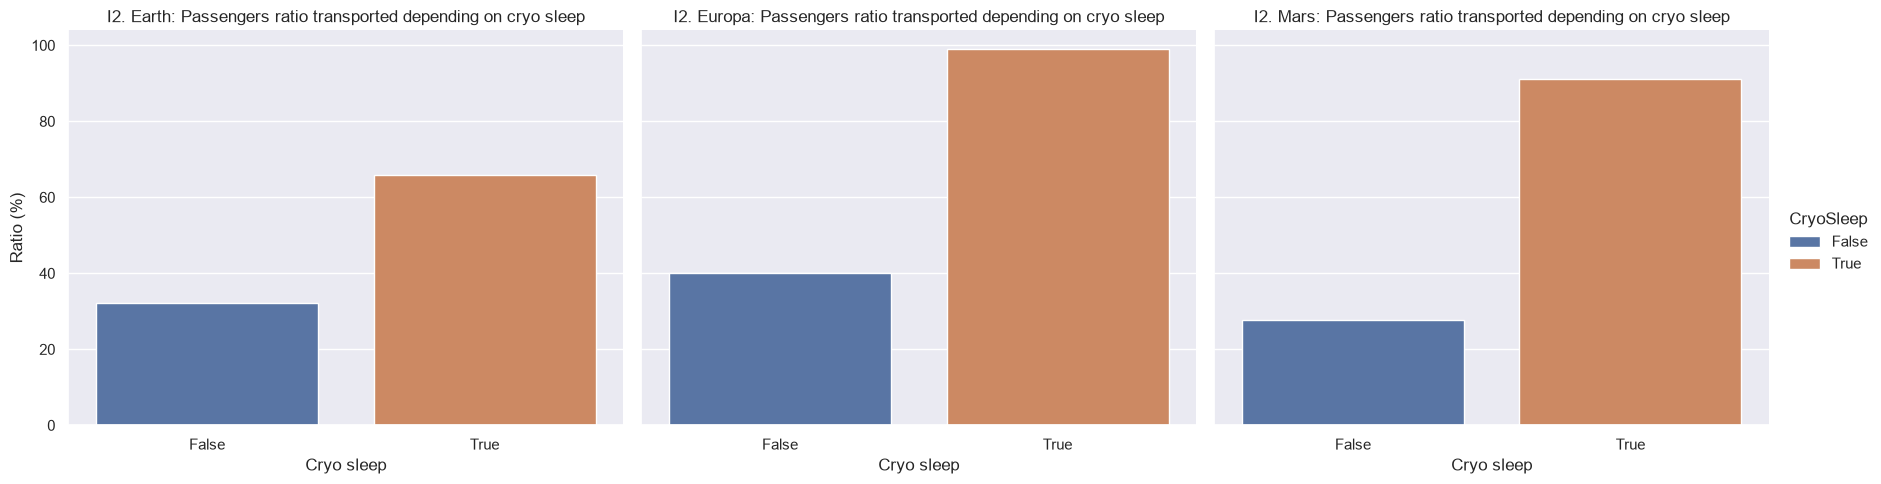

In [64]:
spaceship_titanic_df_i = spaceship_titanic_df[~spaceship_titanic_df[['HomePlanet', 'Destination', 'CryoSleep', 'Transported', 'AgeGroup', 'VIP']].isna().any(axis = 1)]

pom_ratio_transported_by_cryosleep = spaceship_titanic_df_i.groupby('CryoSleep').agg(
    pom_count = ('CryoSleep', "count")
)

ratio_transported_by_cryosleep = spaceship_titanic_df_i[spaceship_titanic_df_i.Transported == True].groupby(['CryoSleep']).agg(
    ratio = ('CryoSleep', "count")
)
ratio_transported_by_cryosleep = ratio_transported_by_cryosleep.merge(pom_ratio_transported_by_cryosleep, on = 'CryoSleep', how = 'left')
ratio_transported_by_cryosleep['ratio'] = ratio_transported_by_cryosleep['ratio'] / ratio_transported_by_cryosleep['pom_count'] * 100

ax = sns.barplot(
    data = ratio_transported_by_cryosleep,
    x = 'CryoSleep',
    hue = 'CryoSleep',
    y = 'ratio'
)

plt.title('I1. Passengers ratio transported depending on cryo sleep')
plt.xlabel('Cryo sleep')
plt.ylabel('Ratio (%)')

plt.show()

pom_homeplanet_ratio_transported_by_cryosleep = spaceship_titanic_df_i.groupby(['HomePlanet', 'CryoSleep']).agg(
    pom_count = ('CryoSleep', "count")
)

homeplanet_ratio_transported_by_cryosleep = spaceship_titanic_df_i[spaceship_titanic_df_i.Transported == True].groupby(['HomePlanet', 'CryoSleep']).agg(
    ratio = ('CryoSleep', "count")
)

homeplanet_ratio_transported_by_cryosleep = homeplanet_ratio_transported_by_cryosleep.merge(pom_homeplanet_ratio_transported_by_cryosleep, on = ['HomePlanet', 'CryoSleep'], how = 'left')
homeplanet_ratio_transported_by_cryosleep['ratio'] = homeplanet_ratio_transported_by_cryosleep['ratio'] / homeplanet_ratio_transported_by_cryosleep['pom_count'] * 100

g = sns.catplot(
    kind = 'bar',
    data = homeplanet_ratio_transported_by_cryosleep,
    x = 'CryoSleep',
    hue = 'CryoSleep',
    y = 'ratio',
    col = 'HomePlanet',
    aspect = 1.2
)

g.set_axis_labels('Cryo sleep', 'Ratio (%)')
g.set_titles('I2. {col_name}: Passengers ratio transported depending on cryo sleep')

plt.show()

* Most passengers in CryoSleep are transported (more than 80%)
* Only ~33% of passengers not in CryoSleep are transported<br><br>

* On Europa percentage of transported passengers not in CryoSleep is slightly higher (~40%) than on Earth (~33%) or Mars (~27%)
* Almost every passenger from Europa (~99%) and Mars (~90%) in CryoSleep is transported

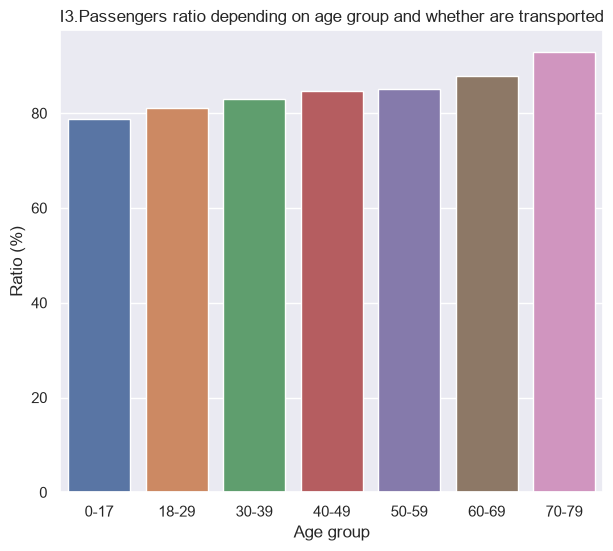

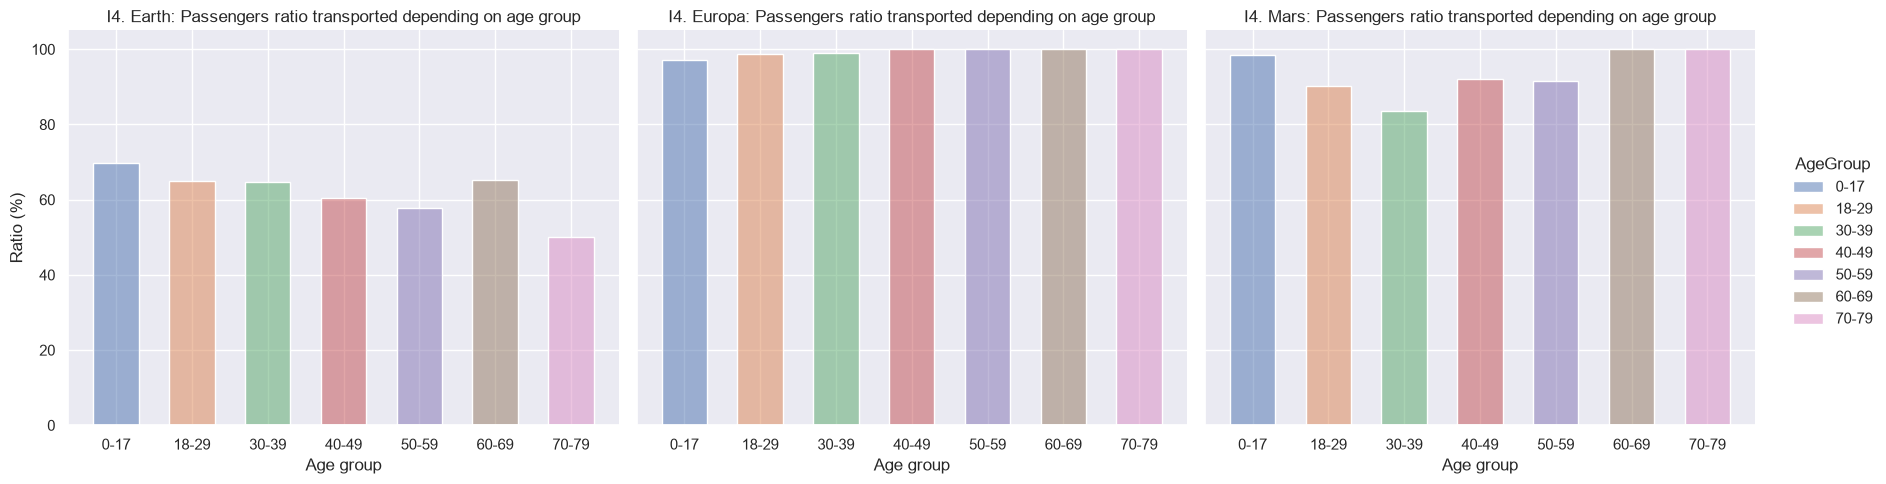

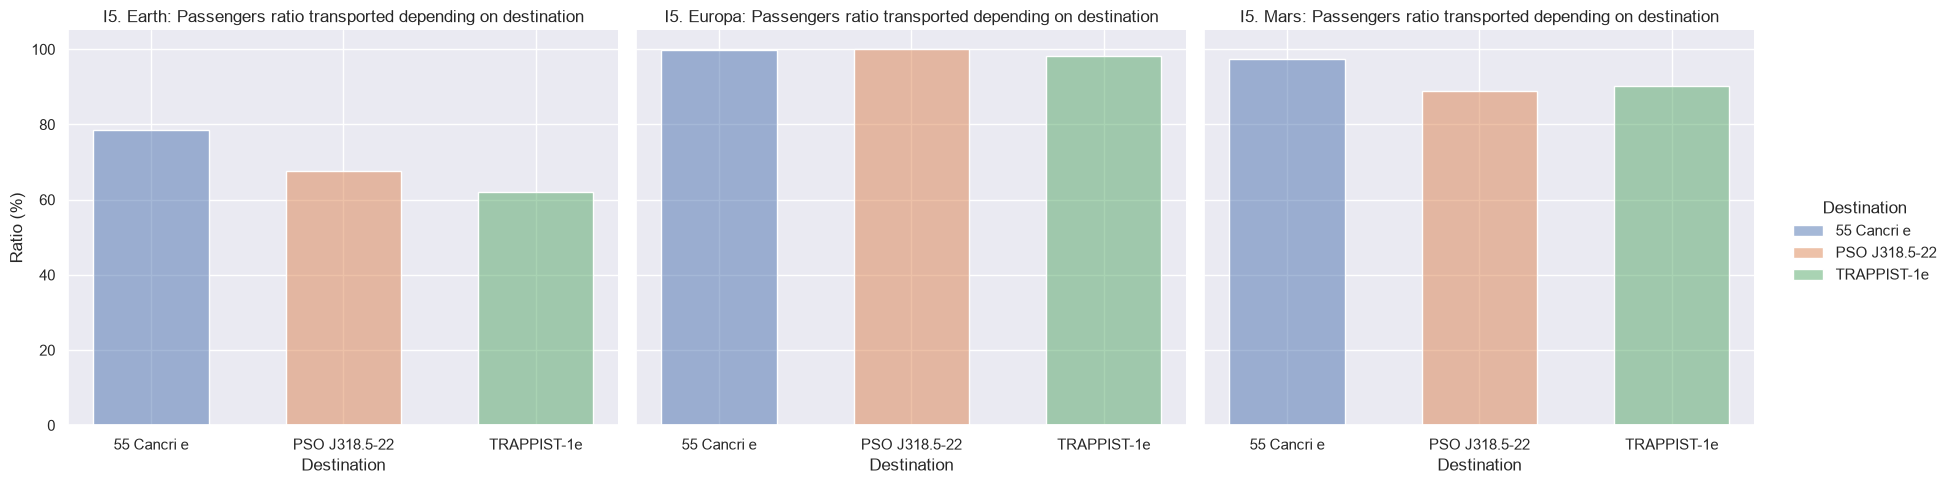

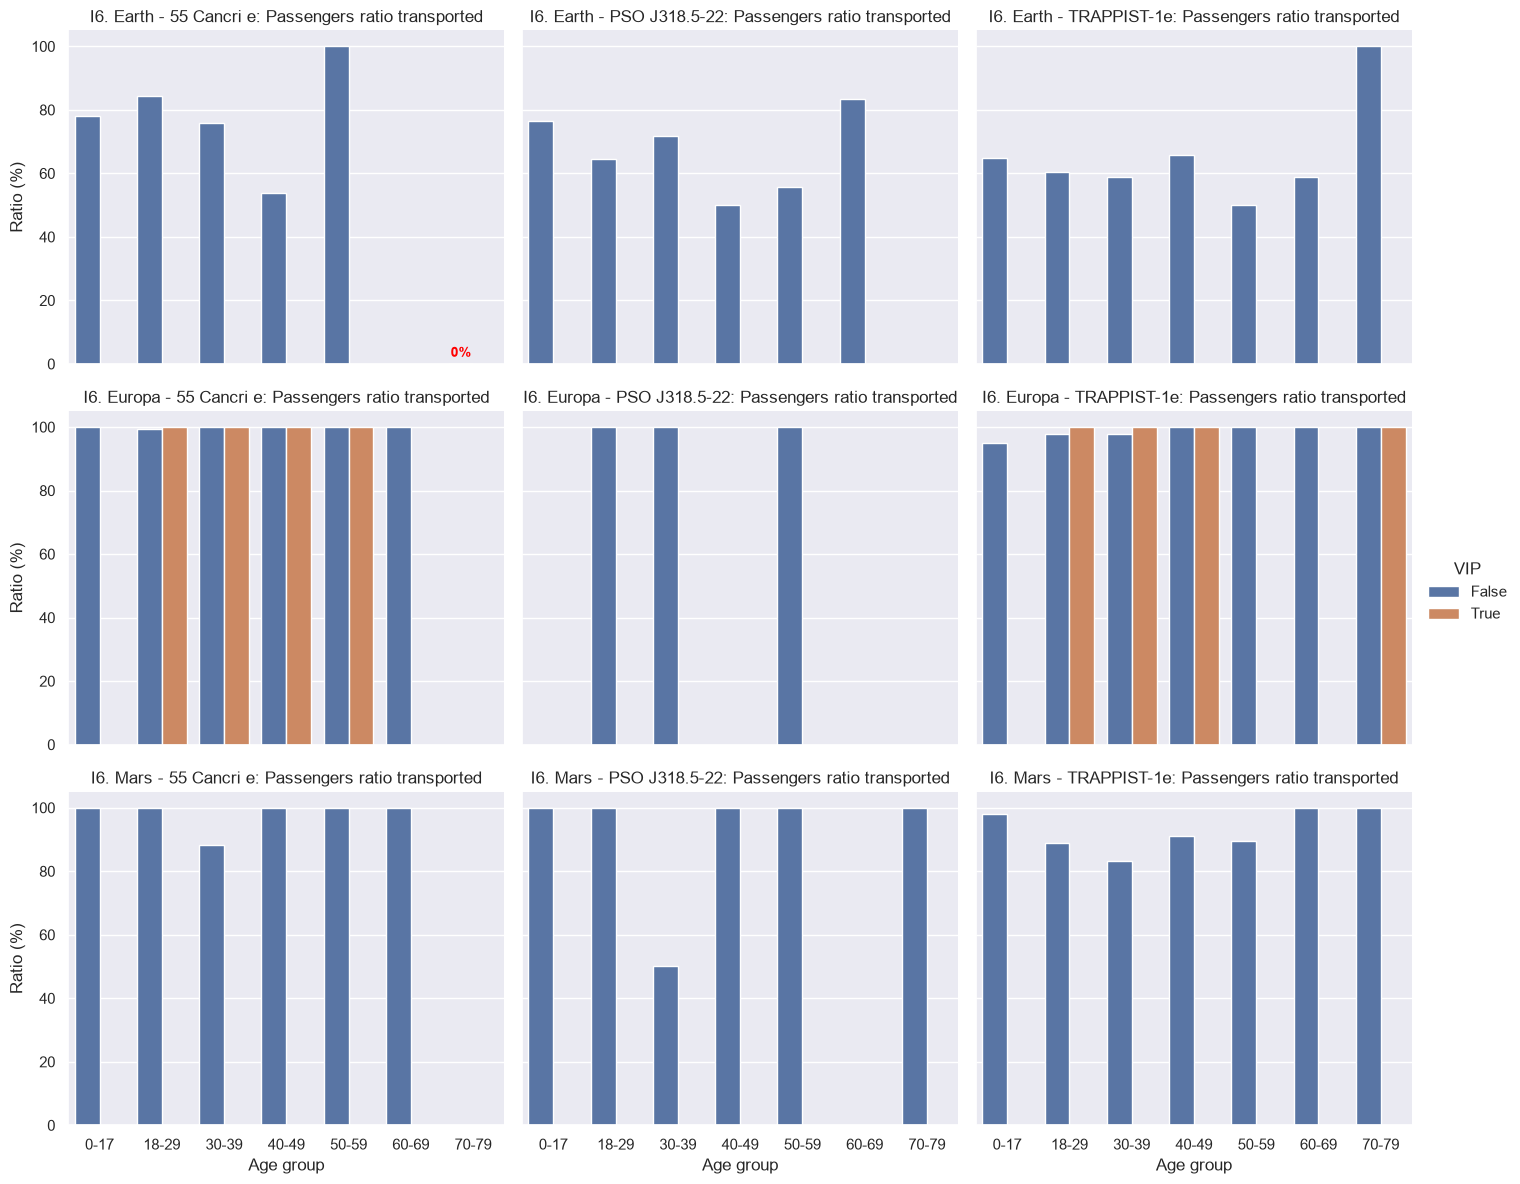

In [65]:
#####
# CRYOSLEEP == TRUE
#####

spaceship_titanic_df_i_1 = spaceship_titanic_df_i[spaceship_titanic_df_i.CryoSleep == True]

pom_ratio_by_agegroup_transported = spaceship_titanic_df_i_1.groupby(['AgeGroup']).agg(
    pom_count = ('AgeGroup', "count")
)

ratio_by_agegroup_transported = spaceship_titanic_df_i_1[spaceship_titanic_df_i_1.Transported == True].groupby(['AgeGroup']).agg(
    ratio = ('AgeGroup', "count")
)
ratio_by_agegroup_transported = ratio_by_agegroup_transported.merge(pom_ratio_by_agegroup_transported, on = 'AgeGroup', how = 'left')
ratio_by_agegroup_transported['ratio'] = ratio_by_agegroup_transported['ratio'] / ratio_by_agegroup_transported['pom_count'] * 100

ax = sns.barplot(
    data = ratio_by_agegroup_transported,
    x = 'AgeGroup',
    hue = 'AgeGroup',
    y = 'ratio',
    dodge = False
)

plt.title('I3.Passengers ratio depending on age group and whether are transported')
plt.xlabel('Age group')
plt.ylabel('Ratio (%)')

plt.show()

pom_homeplanet_ratio_transported_by_agegroup = spaceship_titanic_df_i_1.groupby(['HomePlanet', 'AgeGroup']).agg(
    pom_count = ('AgeGroup', "count")
)

homeplanet_ratio_transported_by_agegroup = spaceship_titanic_df_i_1[spaceship_titanic_df_i_1.Transported == True].groupby(['HomePlanet', 'AgeGroup']).agg(
    ratio = ('AgeGroup', "count")
)
homeplanet_ratio_transported_by_agegroup = homeplanet_ratio_transported_by_agegroup.merge(pom_homeplanet_ratio_transported_by_agegroup, on = ['HomePlanet', 'AgeGroup'], how = 'left')
homeplanet_ratio_transported_by_agegroup['ratio'] = homeplanet_ratio_transported_by_agegroup['ratio'] / homeplanet_ratio_transported_by_agegroup['pom_count'] * 100

g = sns.displot(
    data = homeplanet_ratio_transported_by_agegroup,
    x = 'AgeGroup',
    hue = 'AgeGroup',
    weights = 'ratio',
    col = 'HomePlanet',
    shrink = 0.6,
    aspect = 1.2
)

g.set_axis_labels('Age group', 'Ratio (%)')
g.set_titles('I4. {col_name}: Passengers ratio transported depending on age group')

plt.show()

pom_homeplanet_ratio_transported_by_destination = spaceship_titanic_df_i_1.groupby(['HomePlanet', 'Destination']).agg(
    pom_count = ('Destination', "count")
)

homeplanet_ratio_transported_by_destination = spaceship_titanic_df_i_1[spaceship_titanic_df_i_1.Transported == True].groupby(['HomePlanet', 'Destination']).agg(
    ratio = ('Destination', "count")
)
homeplanet_ratio_transported_by_destination = homeplanet_ratio_transported_by_destination.merge(pom_homeplanet_ratio_transported_by_destination, on = ['HomePlanet', 'Destination'], how = 'left')
homeplanet_ratio_transported_by_destination['ratio'] = homeplanet_ratio_transported_by_destination['ratio'] / homeplanet_ratio_transported_by_destination['pom_count'] * 100

g = sns.displot(
    data = homeplanet_ratio_transported_by_destination,
    x = 'Destination',
    hue = 'Destination',
    weights = 'ratio',
    col = 'HomePlanet',
    shrink = 0.6,
    aspect = 1.2
)

g.set_axis_labels('Destination', 'Ratio (%)')
g.set_titles('I5. {col_name}: Passengers ratio transported depending on destination')

plt.show()

pom_homeplanet_destination_ratio_transported_by_agegroup_vipstatus = spaceship_titanic_df_i_1.groupby(['HomePlanet', 'Destination', 'AgeGroup', 'VIP']).agg(
    pom_count = ('VIP', "count")
)
#print(pom_homeplanet_destination_ratio_transported_by_agegroup_vipstatus.shape)

homeplanet_destination_ratio_transported_by_agegroup_vipstatus = spaceship_titanic_df_i_1[spaceship_titanic_df_i_1.Transported == True].groupby(['HomePlanet', 'Destination', 'AgeGroup', 'VIP']).agg(
    ratio = ('VIP', "count")
)
#print(homeplanet_destination_ratio_transported_by_agegroup_vipstatus.shape)

homeplanet_destination_ratio_transported_by_agegroup_vipstatus = pom_homeplanet_destination_ratio_transported_by_agegroup_vipstatus.merge(homeplanet_destination_ratio_transported_by_agegroup_vipstatus, on = ['HomePlanet', 'Destination', 'AgeGroup', 'VIP'], how = 'left')
homeplanet_destination_ratio_transported_by_agegroup_vipstatus['ratio'] = homeplanet_destination_ratio_transported_by_agegroup_vipstatus['ratio'].fillna(0)

homeplanet_destination_ratio_transported_by_agegroup_vipstatus['ratio'] = homeplanet_destination_ratio_transported_by_agegroup_vipstatus['ratio'] / homeplanet_destination_ratio_transported_by_agegroup_vipstatus['pom_count'] * 100

#print(homeplanet_destination_ratio_transported_by_agegroup_vipstatus.shape)

g = sns.catplot(
    kind = 'bar',
    data = homeplanet_destination_ratio_transported_by_agegroup_vipstatus,
    x = 'AgeGroup',
    hue = 'VIP',
    y = 'ratio',
    row = 'HomePlanet',
    col = 'Destination',
    aspect = 1.2,
    height = 4
)

g.set_axis_labels('Age group', 'Ratio (%)')
g.set_titles('I6. {row_name} - {col_name}: Passengers ratio transported')

for ax in g.axes.flatten():
    for container in ax.containers:
        labels = ['0%' if v == 0 else '' for v in container.datavalues]
        
        ax.bar_label(container, labels = labels, padding = 3, color = 'red', fontsize = 10, fontweight = 'bold')

plt.show()

* On Earth percentage of transported passengers between 70 and 79 years old is slightly lower (50%) than from other age groups (~58% - ~70%)
* On Europa percentage of transported passengers between different age groups is around the same (> 97%)
* On Mars percentage of transported passengers between 18 and 59 years old is lower (~83% - 92%) than from other age groups (> 98%)<br><br>

* Passengers from Earth travelling to TRAPPIST-1e are least likely to be transported (~60%) while passengers travelling to 55 Cancri e are most likely to be transported (~80%)
* On Europa and Mars percentage of transported passengers is similar between different destinations

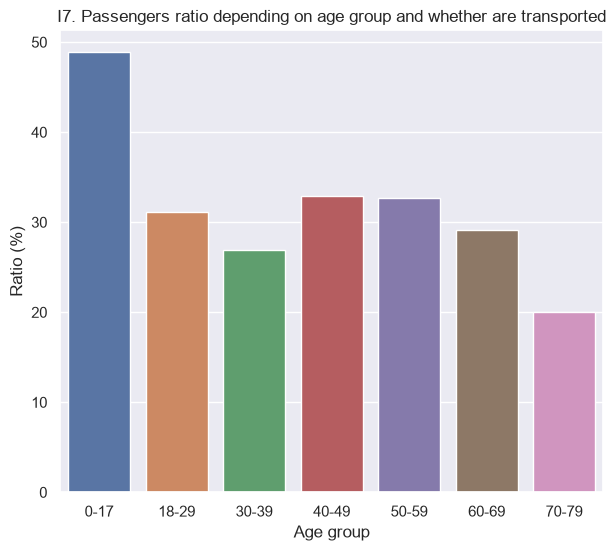

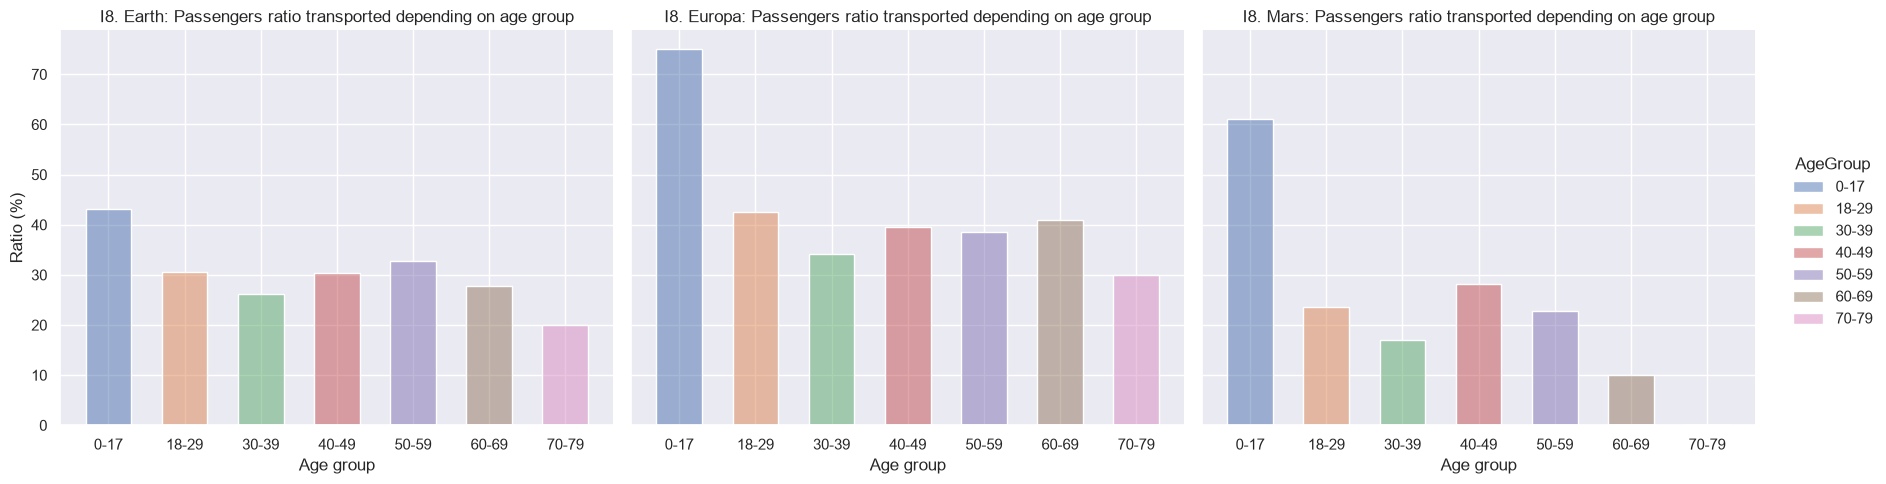

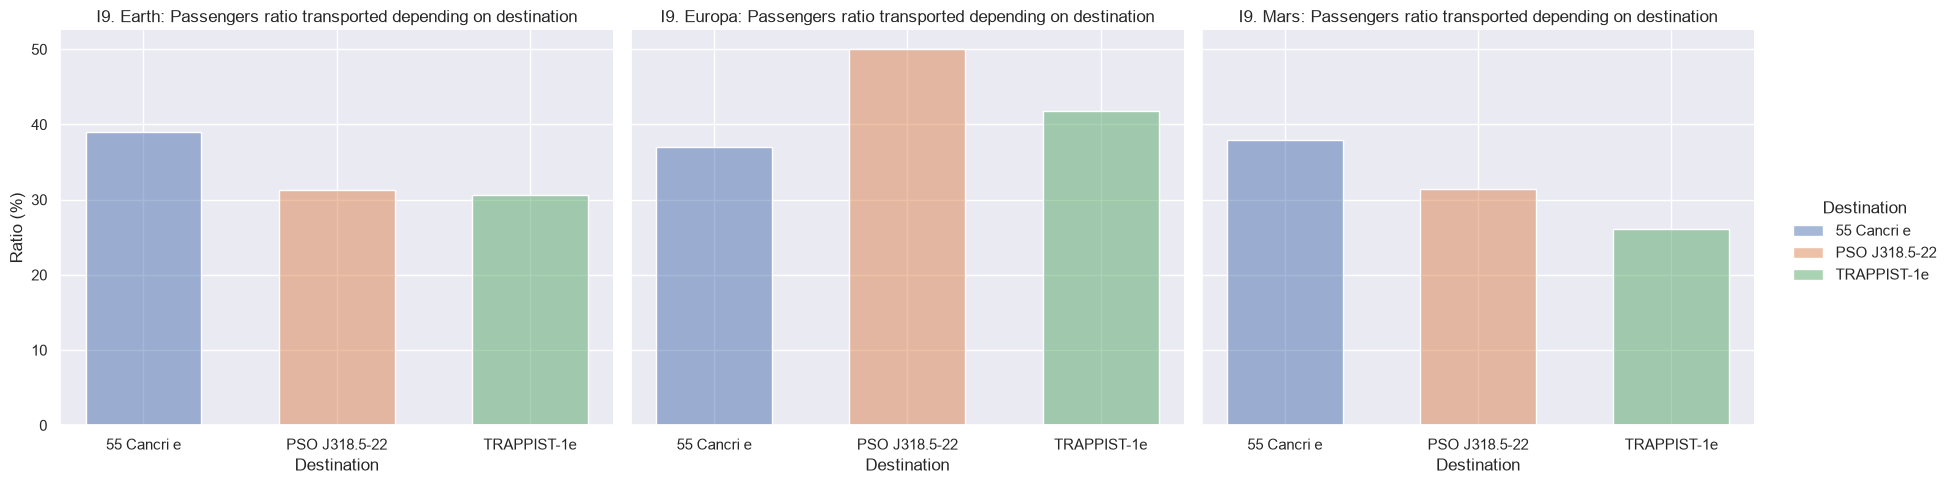

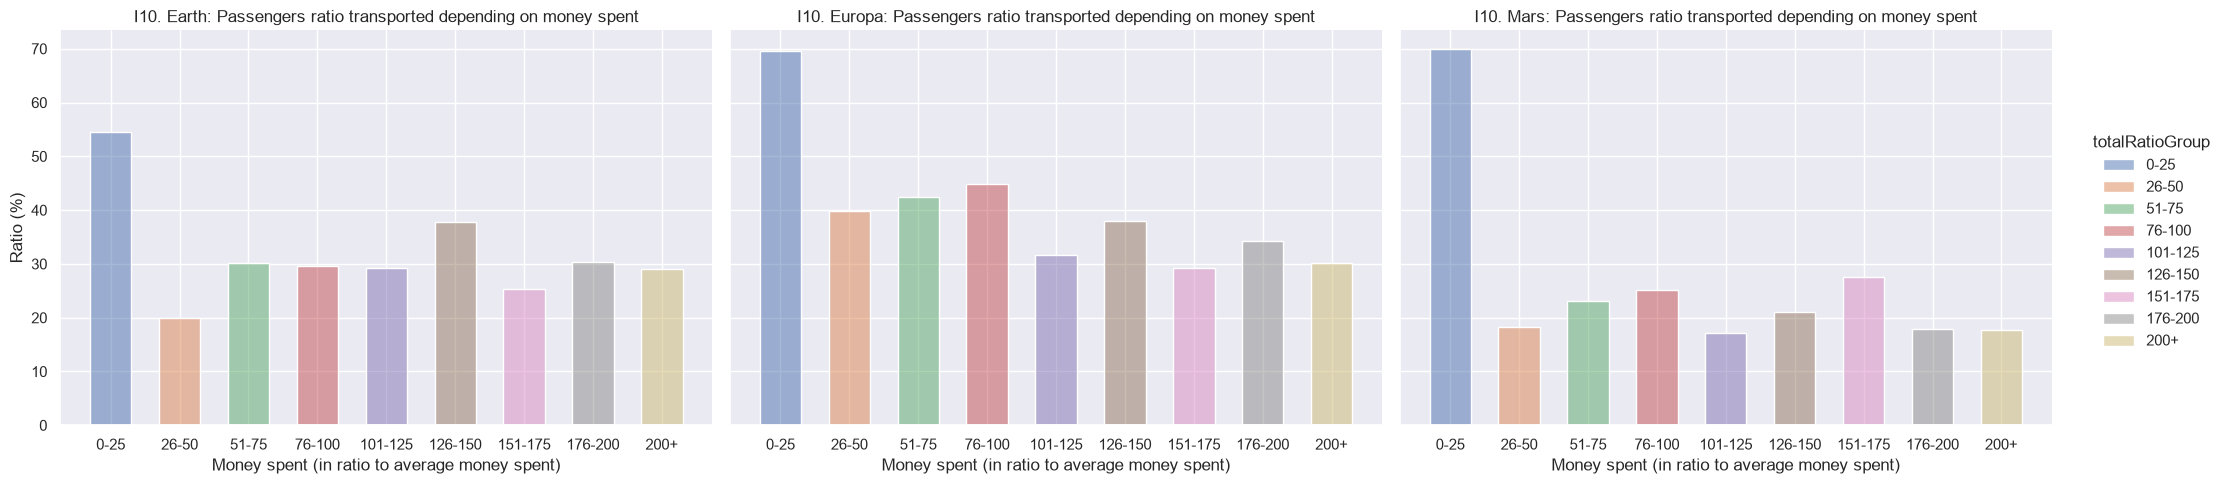

In [66]:
#######
# CRYOSLEEP == FALSE
#######

spaceship_titanic_df_i_2 = spaceship_titanic_df_i[spaceship_titanic_df_i.CryoSleep == False]

pom_ratio_by_agegroup_transported = spaceship_titanic_df_i_2.groupby(['AgeGroup']).agg(
    pom_count = ('AgeGroup', "count")
)

ratio_by_agegroup_transported = spaceship_titanic_df_i_2[spaceship_titanic_df_i_2.Transported == True].groupby(['AgeGroup']).agg(
    ratio = ('AgeGroup', "count")
)
ratio_by_agegroup_transported = ratio_by_agegroup_transported.merge(pom_ratio_by_agegroup_transported, on = 'AgeGroup', how = 'left')
ratio_by_agegroup_transported['ratio'] = ratio_by_agegroup_transported['ratio'] / ratio_by_agegroup_transported['pom_count'] * 100

#display(resK3)

ax = sns.barplot(
    data = ratio_by_agegroup_transported,
    x = 'AgeGroup',
    hue = 'AgeGroup',
    y = 'ratio',
    dodge = False
)

plt.title('I7. Passengers ratio depending on age group and whether are transported')
plt.xlabel('Age group')
plt.ylabel('Ratio (%)')

plt.show()

pom_homeplanet_ratio_transported_by_agegroup = spaceship_titanic_df_i_2.groupby(['HomePlanet', 'AgeGroup']).agg(
    pom_count = ('AgeGroup', "count")
)

homeplanet_ratio_transported_by_agegroup = spaceship_titanic_df_i_2[spaceship_titanic_df_i_2.Transported == True].groupby(['HomePlanet', 'AgeGroup']).agg(
    ratio = ('AgeGroup', "count")
)
homeplanet_ratio_transported_by_agegroup = homeplanet_ratio_transported_by_agegroup.merge(pom_homeplanet_ratio_transported_by_agegroup, on = ['HomePlanet', 'AgeGroup'], how = 'left')
homeplanet_ratio_transported_by_agegroup['ratio'] = homeplanet_ratio_transported_by_agegroup['ratio'] / homeplanet_ratio_transported_by_agegroup['pom_count'] * 100

g = sns.displot(
    data = homeplanet_ratio_transported_by_agegroup,
    x = 'AgeGroup',
    hue = 'AgeGroup',
    weights = 'ratio',
    col = 'HomePlanet',
    shrink = 0.6,
    aspect = 1.2
)

g.set_axis_labels('Age group', 'Ratio (%)')
g.set_titles('I8. {col_name}: Passengers ratio transported depending on age group')

plt.show()

pom_homeplanet_ratio_transported_by_destination = spaceship_titanic_df_i_2.groupby(['HomePlanet', 'Destination']).agg(
    pom_count = ('Destination', "count")
)

homeplanet_ratio_transported_by_destination = spaceship_titanic_df_i_2[spaceship_titanic_df_i_2.Transported == True].groupby(['HomePlanet', 'Destination']).agg(
    ratio = ('Destination', "count")
)
homeplanet_ratio_transported_by_destination = homeplanet_ratio_transported_by_destination.merge(pom_homeplanet_ratio_transported_by_destination, on = ['HomePlanet', 'Destination'], how = 'left')
homeplanet_ratio_transported_by_destination['ratio'] = homeplanet_ratio_transported_by_destination['ratio'] / homeplanet_ratio_transported_by_destination['pom_count'] * 100

#display(resK5)

g = sns.displot(
    data = homeplanet_ratio_transported_by_destination,
    x = 'Destination',
    hue = 'Destination',
    weights = 'ratio',
    col = 'HomePlanet',
    shrink = 0.6,
    aspect = 1.2
)

g.set_axis_labels('Destination', 'Ratio (%)')
g.set_titles('I9. {col_name}: Passengers ratio transported depending on destination')

plt.show()

pom_spaceship_titanic_df_i_2 = spaceship_titanic_df_i_2.groupby('HomePlanet').agg(
    totalMean = ('Total', "mean")
)
spaceship_titanic_df_i_2 = spaceship_titanic_df_i_2.merge(pom_spaceship_titanic_df_i_2, on = 'HomePlanet', how = 'left')
spaceship_titanic_df_i_2['totalRatio'] = spaceship_titanic_df_i_2['Total'] / spaceship_titanic_df_i_2['totalMean'] * 100

temp_borders = [0, 25, 50, 75, 100, 125, 150, 175, 200, 1000000]
temp_labels = ['0-25', '26-50', '51-75', '76-100', '101-125', '126-150', '151-175', '176-200', '200+']

spaceship_titanic_df_i_2['totalRatioGroup'] = pd.cut(
    spaceship_titanic_df_i_2['totalRatio'], 
    bins = temp_borders, 
    labels = temp_labels, 
    right = False
)

pom_homeplanet_ratio_transported_by_moneyspent = spaceship_titanic_df_i_2.groupby(['HomePlanet', 'totalRatioGroup']).agg(
    pom_count = ('totalRatioGroup', "count")
)

homeplanet_ratio_transported_by_moneyspent = spaceship_titanic_df_i_2[spaceship_titanic_df_i_2.Transported == True].groupby(['HomePlanet', 'totalRatioGroup']).agg(
    ratio = ('totalRatioGroup', "count")
)
homeplanet_ratio_transported_by_moneyspent = homeplanet_ratio_transported_by_moneyspent.merge(pom_homeplanet_ratio_transported_by_moneyspent, on = ['HomePlanet', 'totalRatioGroup'], how = 'left')
homeplanet_ratio_transported_by_moneyspent['ratio'] = homeplanet_ratio_transported_by_moneyspent['ratio'] / homeplanet_ratio_transported_by_moneyspent['pom_count'] * 100

g = sns.displot(
    data = homeplanet_ratio_transported_by_moneyspent,
    x = 'totalRatioGroup',
    hue = 'totalRatioGroup',
    weights = 'ratio',
    col = 'HomePlanet',
    shrink = 0.6,
    aspect = 1.4
)

g.set_axis_labels('Money spent (in ratio to average money spent)', 'Ratio (%)')
g.set_titles('I10. {col_name}: Passengers ratio transported depending on money spent')

plt.show()

* From passengers not in CryoSleep children are most likely to be transported (almost 50%) while passengers between 70 and 79 years old are least likely to be transported (20%)<br><br>

* On Earth and Europa percentage of transported passengers is similar between different age groups except for children
* On Mars values vary more from 0% to ~30% of transported passengers depending on age group (excluding children)<br><br>

* Looks like passengers spending least money are more likely to be transported<br>
but it is because most children (who are most likely to be transported) spend nothing
* In other spending groups percentage of transported passengers is mostly similar

In [67]:
spaceship_titanic_df_test = spaceship_titanic_df[['HomePlanet', 'CryoSleep', 'Destination', 'Age', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'Transported', 'CabinDeck', 'CabinSide', 'Total', 'PassengerGroup']]

display(spaceship_titanic_df_test)

,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,CabinDeck,CabinSide,Total,PassengerGroup
0,Europa,False,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,False,B,P,0.0,0001
1,Earth,False,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,True,F,S,736.0,0002
2,Europa,False,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,False,A,S,10383.0,0003
3,Europa,False,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,False,A,S,5176.0,0003
4,Earth,False,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,True,F,S,1091.0,0004
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,Europa,False,55 Cancri e,41.0,True,0.0,6819.0,0.0,1643.0,74.0,False,A,P,8536.0,9276
8689,Earth,True,PSO J318.5-22,18.0,False,0.0,0.0,0.0,0.0,0.0,False,G,S,0.0,9278
8690,Earth,False,TRAPPIST-1e,26.0,False,0.0,0.0,1872.0,1.0,0.0,True,G,S,1873.0,9279
8691,Europa,False,55 Cancri e,32.0,False,0.0,1049.0,0.0,353.0,3235.0,False,E,S,4637.0,9280


In [68]:
print(spaceship_titanic_df_test.isna().sum())

HomePlanet        201
CryoSleep         217
Destination       182
Age               179
VIP               203
RoomService       181
FoodCourt         183
ShoppingMall      208
Spa               183
VRDeck            188
Transported         0
CabinDeck         199
CabinSide         199
Total             908
PassengerGroup      0
dtype: int64


In [69]:
# Plot C3
spaceship_titanic_df_test.loc[(spaceship_titanic_df_test.CabinDeck == 'A') | (spaceship_titanic_df_test.CabinDeck == 'B') | (spaceship_titanic_df_test.CabinDeck == 'C'), 'HomePlanet'] = 'Europa'
spaceship_titanic_df_test.loc[spaceship_titanic_df_test.CabinDeck == 'G', 'HomePlanet'] = 'Earth'

# Plot D1
spaceship_titanic_df_test.loc[(spaceship_titanic_df_test.RoomService > 0) | (spaceship_titanic_df_test.FoodCourt > 0) | (spaceship_titanic_df_test.ShoppingMall > 0) | (spaceship_titanic_df_test.Spa > 0) | (spaceship_titanic_df_test.VRDeck > 0), 'CryoSleep'] = False
spaceship_titanic_df_test.loc[spaceship_titanic_df_test.CryoSleep == True, ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'Total']] = 0

# Plot E2
spaceship_titanic_df_test.loc[spaceship_titanic_df_test.HomePlanet == 'Earth', 'VIP'] = False
spaceship_titanic_df_test.loc[(spaceship_titanic_df_test.CryoSleep == True) & (spaceship_titanic_df_test.VIP == True), 'HomePlanet'] = 'Europa'
spaceship_titanic_df_test.loc[(spaceship_titanic_df_test.HomePlanet == 'Mars') & (spaceship_titanic_df_test.VIP == True), 'CryoSleep'] = False

# Plot E3
spaceship_titanic_df_test.loc[spaceship_titanic_df_test.Age < 18, 'VIP'] = False

# Plot E4
spaceship_titanic_df_test.loc[(spaceship_titanic_df_test.Destination == '55 Cancri e') & (spaceship_titanic_df_test.VIP == True), 'HomePlanet'] = 'Europa'

spaceship_titanic_df_test.loc[spaceship_titanic_df_test.Age < 13, ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'Total']] = 0

spaceship_titanic_df_test.loc[spaceship_titanic_df_test.PassengerGroup.isin(spaceship_titanic_df_test[~spaceship_titanic_df_test.HomePlanet.isna()].PassengerGroup.unique()), 'HomePlanet'] = spaceship_titanic_df_test[~spaceship_titanic_df_test.HomePlanet.isna()].groupby('PassengerGroup').HomePlanet.first()[spaceship_titanic_df_test[spaceship_titanic_df_test.PassengerGroup.isin(spaceship_titanic_df_test[~spaceship_titanic_df_test.HomePlanet.isna()].PassengerGroup.unique())].PassengerGroup].values
spaceship_titanic_df_test.loc[spaceship_titanic_df_test.PassengerGroup.isin(spaceship_titanic_df_test[~spaceship_titanic_df_test.CabinSide.isna()].PassengerGroup.unique()), 'CabinSide'] = spaceship_titanic_df_test[~spaceship_titanic_df_test.CabinSide.isna()].groupby('PassengerGroup').CabinSide.first()[spaceship_titanic_df_test[spaceship_titanic_df_test.PassengerGroup.isin(spaceship_titanic_df_test[~spaceship_titanic_df_test.CabinSide.isna()].PassengerGroup.unique())].PassengerGroup].values

In [70]:
# Plot B5
spaceship_titanic_df_test.loc[(spaceship_titanic_df_test.Destination.isna()) & (spaceship_titanic_df_test.HomePlanet == 'Mars'), 'Destination'] = 'TRAPPIST-1e'

# Plot B6
spaceship_titanic_df_test.loc[(spaceship_titanic_df_test.HomePlanet.isna()) & (spaceship_titanic_df_test.Destination == 'PSO J318.5-22'), 'HomePlanet'] = 'Earth'

# Plot C5
spaceship_titanic_df_test.loc[(spaceship_titanic_df_test.CabinDeck.isna()) & (spaceship_titanic_df_test.HomePlanet == 'Earth') & (spaceship_titanic_df_test.CryoSleep == True), 'CabinDeck'] = 'G'

# Plot C6
spaceship_titanic_df_test.loc[(spaceship_titanic_df_test.Destination.isna()) & ((spaceship_titanic_df_test.CabinDeck == 'E') | (spaceship_titanic_df_test.CabinDeck == 'F')), 'Destination'] = 'TRAPPIST-1e'

# Plot F1
spaceship_titanic_df_test.loc[(spaceship_titanic_df_test.HomePlanet.isna()) & (spaceship_titanic_df_test.Total > 4000), 'HomePlanet'] = 'Europa'
# Plot F7
spaceship_titanic_df_test.loc[(spaceship_titanic_df_test.HomePlanet.isna()) & (spaceship_titanic_df_test.FoodCourt > 1625), 'HomePlanet'] = 'Europa'

spaceship_titanic_df_test.loc[(spaceship_titanic_df_test[['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']].isna().any(axis = 1)) & ((spaceship_titanic_df_test[['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']] == 0).sum(axis=1) == 4), ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'Total']] = 0

spaceship_titanic_df_test.loc[(spaceship_titanic_df_test.CryoSleep.isna()) & (spaceship_titanic_df_test.Total == 0) & (spaceship_titanic_df_test.Age > 12), 'CryoSleep'] = True

In [71]:
spaceship_titanic_df_test.loc[spaceship_titanic_df_test.CryoSleep.isna(), 'CryoSleep'] = False

spaceship_titanic_df_test.loc[spaceship_titanic_df_test.VIP.isna(), 'VIP'] = False

spaceship_titanic_df_test.loc[spaceship_titanic_df_test.HomePlanet.isna(), 'HomePlanet'] = 'Earth'
spaceship_titanic_df_test.loc[spaceship_titanic_df_test.Destination.isna(), 'Destination'] = 'TRAPPIST-1e'

spaceship_titanic_df_test.loc[(spaceship_titanic_df_test.CabinDeck.isna()) & (spaceship_titanic_df_test.HomePlanet == 'Earth'), 'CabinDeck'] = 'G'
spaceship_titanic_df_test.loc[(spaceship_titanic_df_test.CabinDeck.isna()) & (spaceship_titanic_df_test.HomePlanet == 'Europa'), 'CabinDeck'] = 'B'
spaceship_titanic_df_test.loc[(spaceship_titanic_df_test.CabinDeck.isna()) & (spaceship_titanic_df_test.HomePlanet == 'Mars'), 'CabinDeck'] = 'F'

spaceship_titanic_df_test.loc[spaceship_titanic_df_test.RoomService.isna(), 'RoomService'] = spaceship_titanic_df_test.groupby(['HomePlanet']).RoomService.mean()[spaceship_titanic_df_test[spaceship_titanic_df_test.RoomService.isna()].HomePlanet].values
spaceship_titanic_df_test.loc[spaceship_titanic_df_test.FoodCourt.isna(), 'FoodCourt'] = spaceship_titanic_df_test.groupby(['HomePlanet']).FoodCourt.mean()[spaceship_titanic_df_test[spaceship_titanic_df_test.FoodCourt.isna()].HomePlanet].values
spaceship_titanic_df_test.loc[spaceship_titanic_df_test.ShoppingMall.isna(), 'ShoppingMall'] = spaceship_titanic_df_test.groupby(['HomePlanet']).ShoppingMall.mean()[spaceship_titanic_df_test[spaceship_titanic_df_test.ShoppingMall.isna()].HomePlanet].values
spaceship_titanic_df_test.loc[spaceship_titanic_df_test.Spa.isna(), 'Spa'] = spaceship_titanic_df_test.groupby(['HomePlanet']).Spa.mean()[spaceship_titanic_df_test[spaceship_titanic_df_test.Spa.isna()].HomePlanet].values
spaceship_titanic_df_test.loc[spaceship_titanic_df_test.VRDeck.isna(), 'VRDeck'] = spaceship_titanic_df_test.groupby(['HomePlanet']).VRDeck.mean()[spaceship_titanic_df_test[spaceship_titanic_df_test.VRDeck.isna()].HomePlanet].values
spaceship_titanic_df_test['Total'] = spaceship_titanic_df_test[['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']].sum(axis = 1)

spaceship_titanic_df_test.loc[spaceship_titanic_df_test.Age.isna(), 'Age'] = spaceship_titanic_df_test.groupby(['HomePlanet']).Age.median()[spaceship_titanic_df_test[spaceship_titanic_df_test.Age.isna()].HomePlanet].values

spaceship_titanic_df_test.loc[spaceship_titanic_df_test.CabinSide.isna(), 'CabinSide'] = 'P'


spaceship_titanic_df_test = spaceship_titanic_df_test.drop('PassengerGroup', axis = 1)

In [72]:
spaceship_titanic_df_model = pd.get_dummies(spaceship_titanic_df_test, drop_first = True)

X = spaceship_titanic_df_model.drop('Transported', axis = 1)
y = spaceship_titanic_df_model['Transported']

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size = 0.2, random_state = 42)

rf_model = RandomForestClassifier(n_estimators = 500, max_depth = 10, random_state = 42)
rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_val)
accuracy = accuracy_score(y_val, y_pred)

print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 79.07%


In [73]:
spaceship_titanic_df_model = pd.get_dummies(spaceship_titanic_df_test, drop_first = True)

X = spaceship_titanic_df_model.drop(['Transported'], axis = 1)
y = spaceship_titanic_df_model['Transported']

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size = 0.2, random_state = 42)

xgb_model = XGBClassifier(n_estimators = 500, max_depth = 6, learning_rate = 0.04, random_state = 42)
xgb_model.fit(X_train, y_train)

y_pred = xgb_model.predict(X_val)
accuracy = accuracy_score(y_val, y_pred)

print(f"Accuracy (XGBoost): {accuracy * 100:.2f}%")

Accuracy (XGBoost): 80.16%
